# CO2 - Data Challenge Project Work 2023 - Basil Imoberdorf

## Multiclass classification of dry bean varieties

## 1. Introduction

Dry bean (Phaseolus vulgaris L.) is the most important and the most produced pulse (Fabaceae - Leguminosae) over the world. 
Dry bean plays an important role in agriculture in Turkey where the seeds of beans cultivated are divided into varieties by taking into account the features of the form, shape, type and structure of the Turkish Standards Institute, as well as the market situation. The most well-known of these bean varieties are Barbunya, Bombay, Cali, Dermason, Horoz, Seker and Sira.

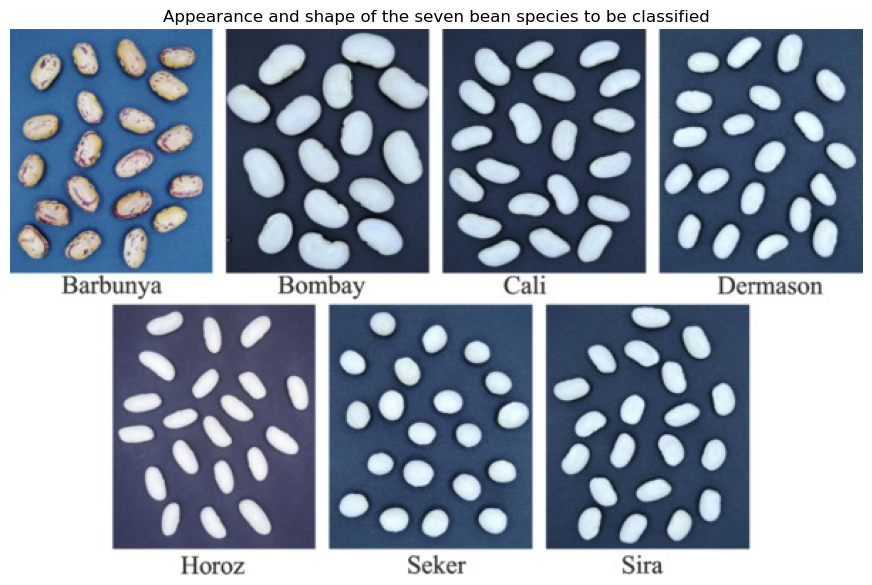

In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
plt.figure(figsize=(11, 10))
plt.imshow(mpimg.imread('BeanClasses.jpg')) # Show a picture of all classes. Taken form Murat Koklu et al.
plt.axis('off')
plt.title('Appearance and shape of the seven bean species to be classified');

These beans are often cultivated together, and multiple varieties may be grown in close proximity within the same field, facilitating cross-pollination and enhancing genetic diversity. Since different populations which contain different genotypes are cultivated, the final products contain different species of seeds. Thus, when the dry bean seeds obtained from population cultivation are released to the market without being separated by species, the market value decreases immensely (Varankaya and Ceyhan, 2012).

Eliminating the disadvantageous situation caused by population cultivation will provide an economic benefit to the producer as a uniform type of bean is obtained. In addition, examination and pricing of products in the market is determined by experts. Because of the human factor, this process is error-prone and not entirely objective. In recent years, the use of data mining and artificial intelligence techniques to solve forecasting and classification problems in agriculture has become widespread.

Manual classification and sorting of bean seeds is a difficult process. Furthermore, this method is very time consuming and inefficient, especially with high production volumes. For these reasons, automatic classification models for sorting and grading are required. The objective is to provide a method for obtaining uniform seed varieties from crop production, which is in the form of population, so the seeds are not certified as a sole variety.

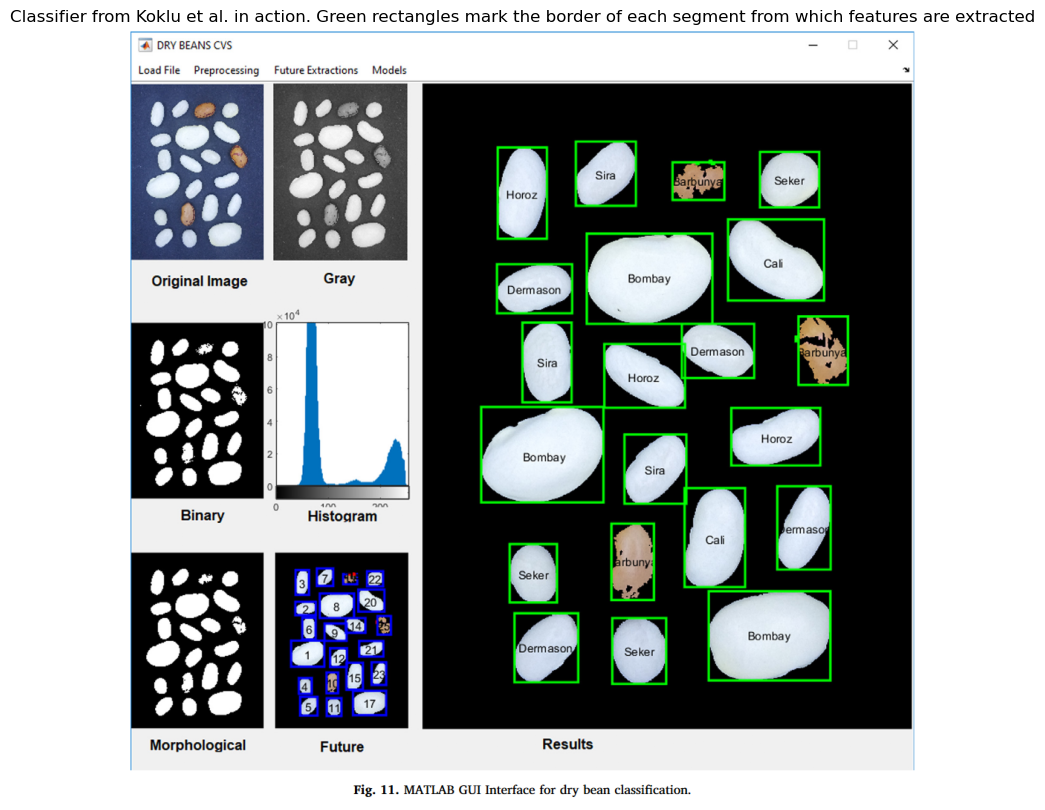

In [2]:
plt.figure(figsize=(11, 10))
plt.imshow(mpimg.imread('BeansClassSolo.png')) # Show a picture of all classes. Taken form Murat Koklu et al. 
plt.axis('off') 
plt.title('Classifier from Koklu et al. in action. Green rectangles mark the border of each segment from which features are extracted');

## 2. Data Exploration

For the classification models, images of **13'611** grains of 7 different registered dry beans were taken with a high-resolution camera. The images were subjected to segmentation and feature extraction stages, and a total of **16 features**; 12 dimension and 4 shape forms, were obtained from the grains. There are by design only numerical features and no missing values in the data which greatly facilltates the pre-processing. For more detail on how the data was compiled please refer to the orignal paper by Murat Koklu et al. where the data set was first published. https://doi.org/10.1016/j.compag.2020.105507

The extracted features are based on the pixels within a given segment, which always encloses a single bean. 
The features are as follows:

1. **Area (A)**: The area of a bean zone and the number of pixels within its boundaries.

2. **Perimeter (P)**: Bean circumference is defined as the length of its border.

3. **Major axis length (L)**: The distance between the ends of the longest line that can be drawn from a bean.

4. **Minor axis length (l)**: The longest line that can be drawn from the bean while standing perpendicular to the major axis.

5. **Aspect ratio (K)**: Defines the relationship between L and l. $K = \frac{L}{l}$

6. **Eccentricity (Ec)**: Eccentricity of the ellipse having the same moments as the region.

7. **Convex area (C)**: Number of pixels in the smallest convex polygon that can contain the area of a bean seed.

8. **Equivalent diameter (Ed)**: The diameter of a circle having the same area as a bean seed area. $d = \sqrt{\frac{4A}{\pi}}$

9. **Extent (Ex)**: The ratio of the pixels in the bounding box to the bean area. $Ex = \frac{A}{A_B}$ where $A_B$ is the bound area by the rectangle

10. **Solidity (S)**: The ratio of the pixels in the convex shell to those found in beans. $S = \frac{A}{C}$

11. **Roundness (R)**: Calculated with the following formula: $R = \frac{4\pi A}{P^2}$

12. **Compactness (CO)**: Measures the roundness of an object: $CO = \frac{Ed}{L}$

13. **Shape Factor 1 (SF1)**: $SF1 = \frac{L}{A}$

14. **Shape Factor 2 (SF2)**: $SF2 = \frac{l}{A}$

15. **Shape Factor 3 (SF3)**: $SF3 = \frac{4A}{lL\pi}$

16. **Shape Factor 4 (SF4)**: $SF3 = \frac{4A}{L^2pi}$


In [3]:
import pandas as pd

# load data set and print general info
Bean_DataFrame = pd.read_excel('Dry_Bean_Dataset.xlsx')
print(Bean_DataFrame.describe())
print(Bean_DataFrame.info())

# Separate features and target
X = Bean_DataFrame.iloc[:, :-1] # nummerical data matrix / design matrix 
y = Bean_DataFrame.iloc[:, -1]  # vector of strings containg the lables of the target classes 

                Area     Perimeter  MajorAxisLength  MinorAxisLength  \
count   13611.000000  13611.000000     13611.000000     13611.000000   
mean    53048.284549    855.283459       320.141867       202.270714   
std     29324.095717    214.289696        85.694186        44.970091   
min     20420.000000    524.736000       183.601165       122.512653   
25%     36328.000000    703.523500       253.303633       175.848170   
50%     44652.000000    794.941000       296.883367       192.431733   
75%     61332.000000    977.213000       376.495012       217.031741   
max    254616.000000   1985.370000       738.860153       460.198497   

       AspectRation  Eccentricity     ConvexArea  EquivDiameter        Extent  \
count  13611.000000  13611.000000   13611.000000   13611.000000  13611.000000   
mean       1.583242      0.750895   53768.200206     253.064220      0.749733   
std        0.246678      0.092002   29774.915817      59.177120      0.049086   
min        1.024868      0.

Now let's first check the distribution of instances across the target classes and see if the data set is imbalanced

A total of 13611 instances are in the data set.
---------------------------------
2027 instances of Seker    beans
1322 instances of Barbunya beans
522 instances of Bombay   beans
1630 instances of Cali     beans
1928 instances of Horoz    beans
2636 instances of Sira     beans
3546 instances of Dermason beans


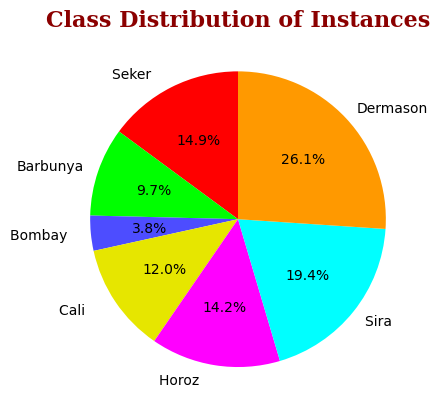

In [4]:
import numpy as np

# Get the number of samples / instances per class
nSamples_per_Class = [sum((y == 'SEKER').astype(int).values),
                      sum((y == 'BARBUNYA').astype(int).values),
                      sum((y == 'BOMBAY').astype(int).values),
                      sum((y == 'CALI').astype(int).values),
                      sum((y == 'HOROZ').astype(int).values),
                      sum((y == 'SIRA').astype(int).values),
                      sum((y == 'DERMASON').astype(int).values)]

# Check for imbalanced data using a pie chart to display the distribution of the instances among the target classes
Target_Class_Strings = ['Seker   ', 'Barbunya', 'Bombay  ', 'Cali    ', 'Horoz   ', 'Sira    ', 'Dermason']
Colors = np.array([(1,0,0), (0,1,0), (.3,.3,1), (.9,.9,0), (1,0,1), (0,1,1), (1,.6,0)]) # These colors are used for consistency, as far as possible, in all plots
Font = {'family':'serif', 'color':'darkred', 'weight':'bold', 'size': 16}
plt.pie(nSamples_per_Class, labels=Target_Class_Strings, autopct='%1.1f%%', startangle=90, colors=Colors)
plt.title('Class Distribution of Instances', fontdict=Font)

# Print the number of instances in each class
print('A total of \033[1m' + str(sum(nSamples_per_Class)) + '\033[0m instances are in the data set.\n---------------------------------')
for i in range(7):
   # print(Target_Labels[i] + ' has \033[1m' + str(nSamples_per_Class[i]) + '\033[0m observations.')
    print('\033[1m' + str(nSamples_per_Class[i]) + '\033[0m'+ ' instances of \033[1m' + Target_Class_Strings[i] + '\033[0m beans')    

The data set looks fairly imbalanced at first glance. However, the researchers who compiled the data set realized that it is fairly easy to classfy Barbunya and Bombay beans since the have distinct features. Bomby beans are for example significantly larger than the other beans. The set contains more instances of the hard to distinguish beans of Dermason and Sira


Now let's take a look at how the features correlate with each other. Although 16 features are a lot for a seaborn pairplot(), we can draw two 8-by-8 features as a compromise. This means that 128 of the 256 possible feature combinations are not displayed, but it should be enough to get an impression of the correlations.

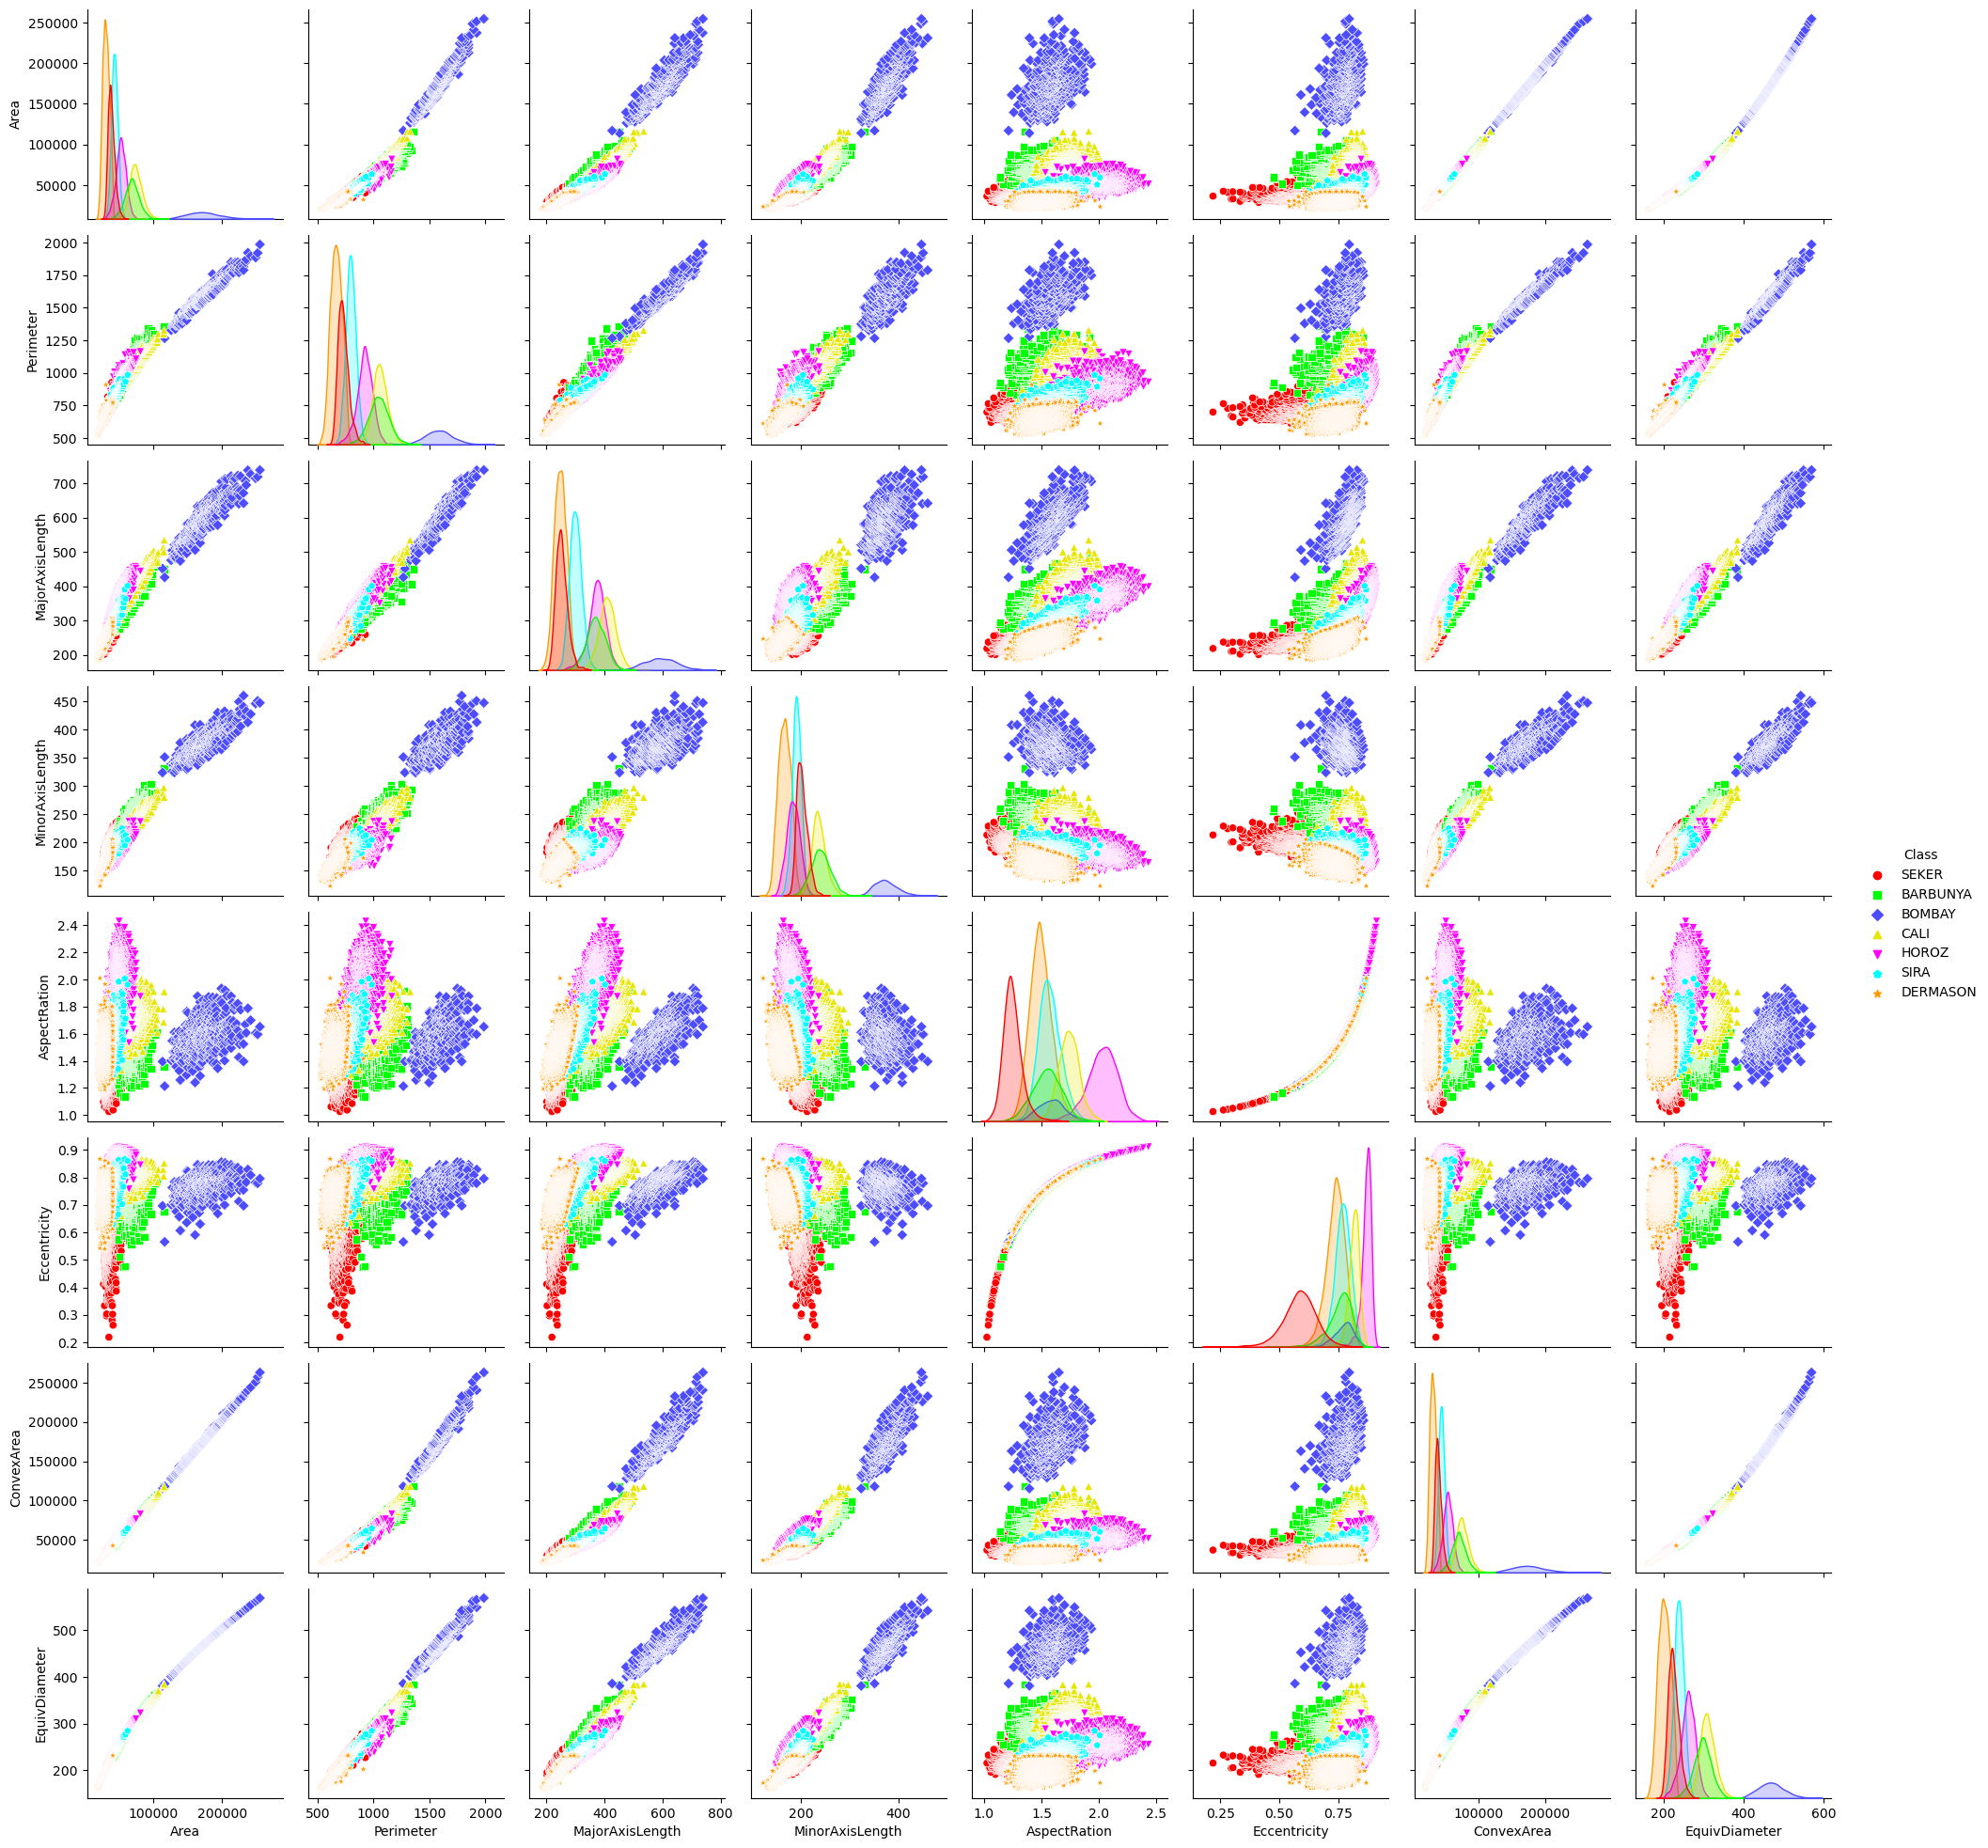

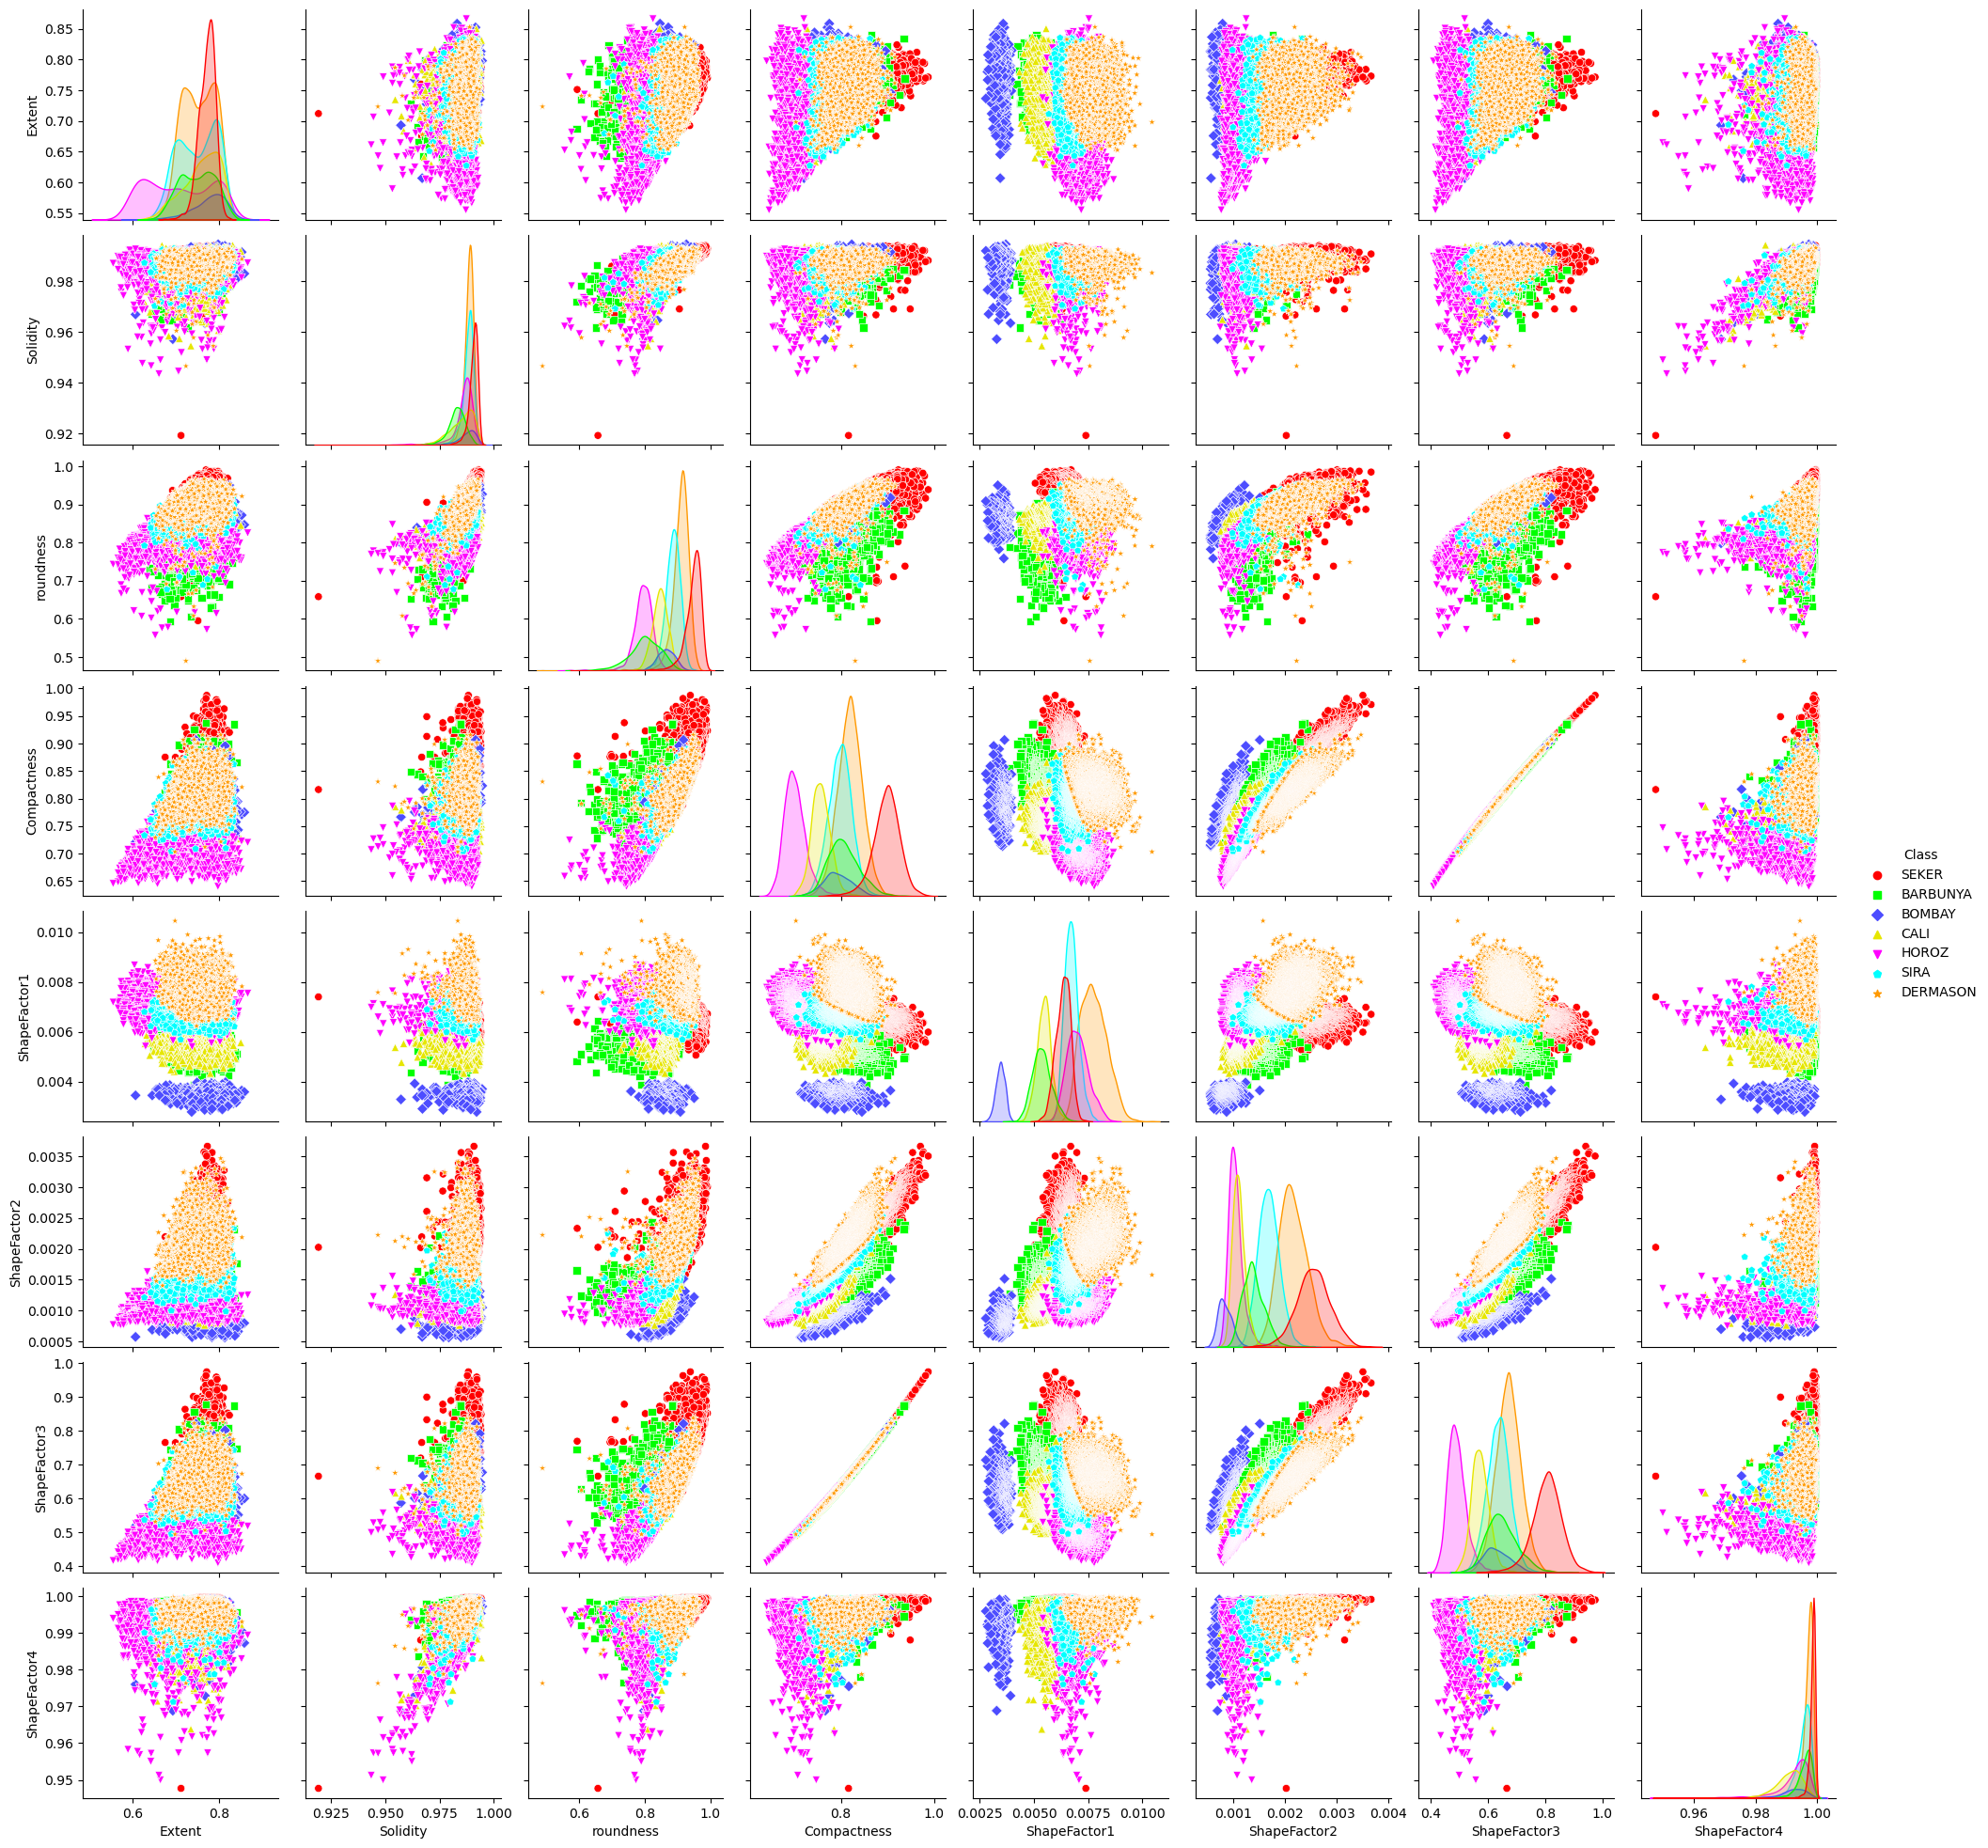

In [5]:
import seaborn as sns
import warnings

warnings.filterwarnings("ignore") # Ignore all warnings produced by seaborn for the sake of clarity.
sns.pairplot( # the first 8 features.
    Bean_DataFrame.iloc[:, [0, 1, 2, 3, 4, 5, 6, 7, -1]],  
    hue='Class',                                       
    palette=Colors.tolist(),                           
    markers=["o", "s", "D", "^", "v", "p", "*"]       
)
sns.pairplot( # the remaining 8 features.
    Bean_DataFrame.iloc[:,[8,9,10,11,12,13,14,15,-1]],
    hue='Class', palette=Colors.tolist(),
    markers=["o", "s", "D", "^", "v", "p", "*"]
); 

The kernel density estimate for the distributions show nice Gaussian distributions for each class. This was somewhat expected as the growth of the beans is likely around a natural optimum/mean with a certain standard deviation.

Also expected were the strong correlations among many of the features such as area and perimeter. But also most of the features that are functions of other features show strong correaltions. 
The shape factors also show interesting correlations and nice clusters for each variety. It will be interesting to see which features or combinations thereof are most useful for classifying the beans.

It is noteworthy that the lengths of the major and minor axes are strongly positively correlated with the area of a bean, but not the ratio of the two. This shows how the information content of a data set can be augmented and improved with the help of feature engineering and without actually having to measure new features.  

With 16 features there are theoretically 256 plots necessary to grasp the full two-feature correlations but the models will work anyway on the 16-dimensional feature space which is impossible to grasp. Nevertheless, these two pairplots should give an impression on how the features are correlated and distributed. These two pair plots correspond to the upper left and the lower right quadrant of the heatmap in the cell below. The heatmap shows positive correlations among the first 8 and the among the last 8 features and negative correleations between the first and last 8 features. 


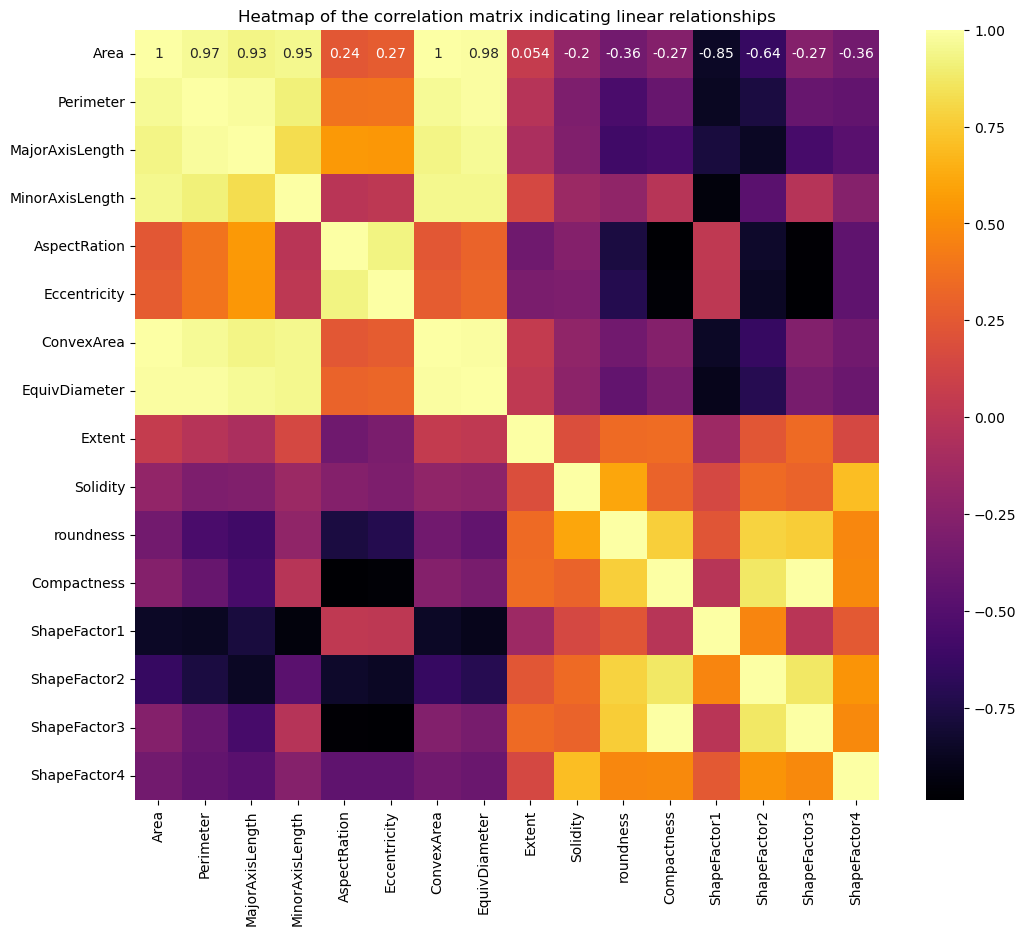

In [6]:
plt.figure(figsize=(12, 10)) # Get the big picture^^
sns.heatmap(X.corr(), cmap='inferno', annot=True)
plt.title('Heatmap of the correlation matrix indicating linear relationships');

## 3. Pre-Processing

As no values are missing, no imputation or removal of instances is required. Furthermore, the data does not contain any categorical features, therefore no encoding is required.

The only thing left before any Machine Learning is done is to scale the data. Five common scaling methods are applieded to transform the features into a more algorithm friendly form. Experimneting with different scaling methods when training the models should get an idea on which scalin is best for which classifier. 

In [7]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import QuantileTransformer
from sklearn.preprocessing import PowerTransformer

# Perform common scaling methods and store them for easy swapping while testing models
X_MinMax = MinMaxScaler().fit_transform(X)
X_Normal = StandardScaler().fit_transform(X)
X_Robust = RobustScaler().fit_transform(X)
X_Quanti = QuantileTransformer().fit_transform(X)
X_PowerT = PowerTransformer().fit_transform(X) # This transformation causes overflow warning/error
warnings.resetwarnings()

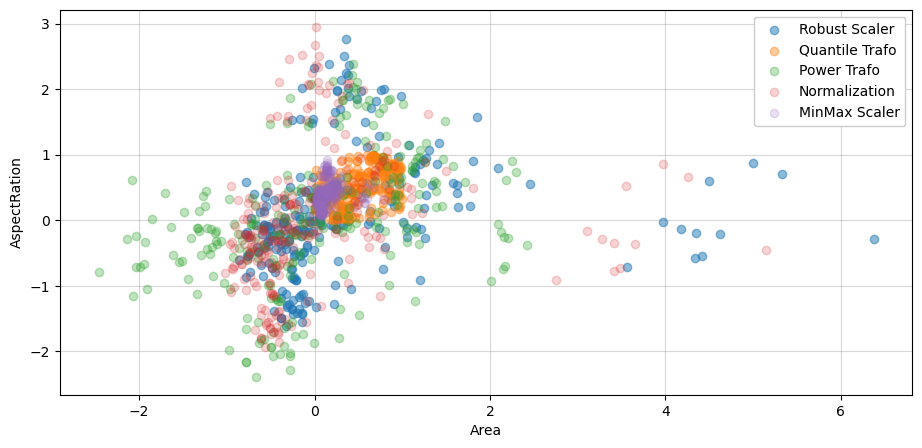

In [8]:
# Show the effect of the different scaling methods using the features 'Area' and 'AspectRatio'
import random
plt.figure(figsize=(11, 5))
RNG = np.array([random.randint(0, 13611) for _ in range(250)]) # plot only a random subset to avoid clutter        
plt.scatter(X_Robust[RNG,0], X_Robust[RNG,4], alpha=0.5, zorder=2, label='Robust Scaler')
plt.scatter(X_Quanti[RNG,0], X_Quanti[RNG,4], alpha=0.4, zorder=2, label='Quantile Trafo')
plt.scatter(X_PowerT[RNG,0], X_PowerT[RNG,4], alpha=0.3, zorder=2, label='Power Trafo')
plt.scatter(X_Normal[RNG,0], X_Normal[RNG,4], alpha=0.2, zorder=2, label='Normalization')
plt.scatter(X_MinMax[RNG,0], X_MinMax[RNG,4], alpha=0.2, zorder=2, label='MinMax Scaler')
# Formating
plt.grid(True, linestyle='-', alpha=0.5, zorder=1)
Feature_Names = X.columns.tolist()
plt.xlabel(Feature_Names[0])
plt.ylabel(Feature_Names[4])
plt.legend(framealpha=1);

## 4. Testing different classifiers

The approach to this problem will be to first create different classfiers and try to find the optimal hyperparameters for each one. The classifiers to be applied are Logistic Regegression, k-Nearest Neighbours (kNN), Support Vector Machines (SVM) and Random Forests (RF).

In the end, the classifier each type with the best found hyperparameters is used in an ensemble voting classifier to see if the optimzed models perform better together. 

In the original paper, kNN, SVM, decision tree and multilayer perceptrons were tested, but no voting classifier as in ensemble learning was constructed. It will be interesting to see if the ensemble of these models can outperform the best classifier in the paper.


## 4.1 Logistic Regression

To apply logistic regression to multi-class problems one has to split the target classes into binary one-versus-rest sets. This means that 7 individal models are created to classfiy the 7 dry bean classes, where each one is trained to predict only one class. To get optimal logistic regerssion models, the effect of using different solvers, different regulariazation penaltys like Ridge (L2) or Lasso (L1) as well as the different scaled data sets are tested.

In [9]:
# Transform targets into one-versus-rest
y_Sekr = (y == 'SEKER'   ).astype('int') 
y_Barb = (y == 'BARBUNYA').astype('int') 
y_Bomb = (y == 'BOMBAY'  ).astype('int') 
y_Cali = (y == 'CALI'    ).astype('int') 
y_Horz = (y == 'HOROZ'   ).astype('int') 
y_Sira = (y == 'SIRA'    ).astype('int') 
y_Deso = (y == 'DERMASON').astype('int') 

# Horzcat these vectors into a matrix so that a for loop can access them column by column for convenient model creation.
y_Collection = pd.concat([y_Sekr, y_Barb, y_Bomb, y_Cali, y_Horz, y_Sira, y_Deso], axis=1)

Average test set accuracy over all classes using scaled features: 97.36 ± 2.21%
----------------------------------------------------------
Average cross-validation (CV) accuracy for each class:
Seker     =  98.28 ± 0.24%
Barbunya  =  98.29 ± 0.36%
Bombay    =  99.99 ± 0.03%
Cali      =  97.73 ± 0.63%
Horoz     =  98.61 ± 0.26%
Sira      =  93.07 ± 0.69%
Dermason  =  95.59 ± 0.54%
Average test set accuracy over all classes using raw features: 92.82 ± 6.43%
----------------------------------------------------------
Average cross-validation (CV) accuracy for each class:
Seker     =  97.1 ± 0.39%
Barbunya  =  95.53 ± 0.74%
Bombay    =  99.99 ± 0.03%
Cali      =  86.62 ± 0.62%
Horoz     =  98.17 ± 0.43%
Sira      =  80.63 ± 0.05%
Dermason  =  92.16 ± 0.79%


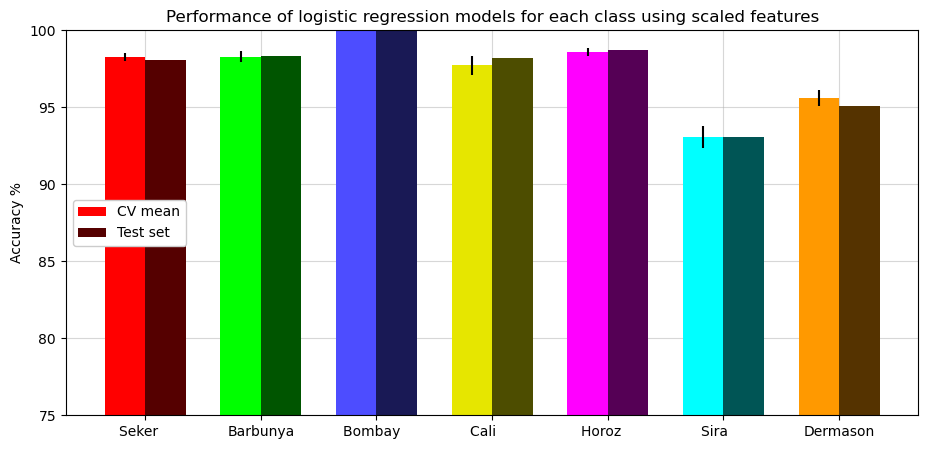

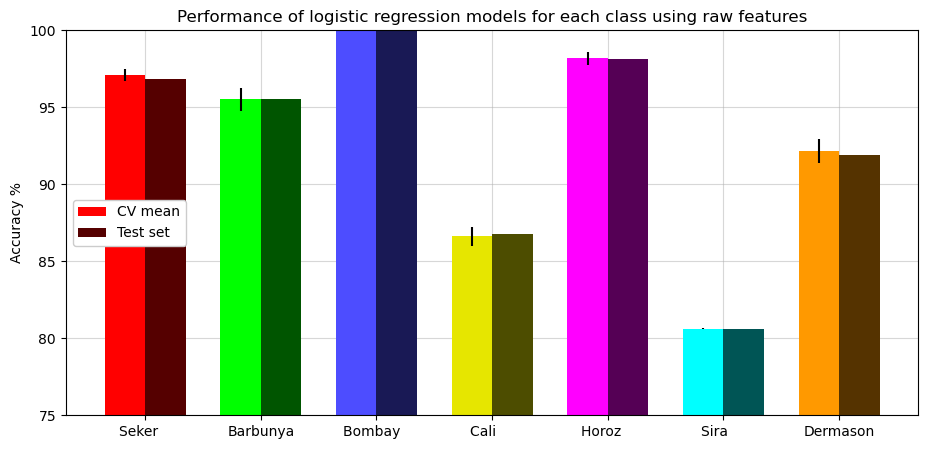

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore") # Ignore warnings issued by the solver due to convergence problems on unscaled data
for j in range(2): # loop to test with vs without scaled features 
    if j == 0:
        X_LogReg = X_Normal
        Str = ' using scaled features'
    else:
        X_LogReg = X
        Str = ' using raw features'
    # Create a test set to asses the performance of the cross validated model
    # Note: 'stratify' ensures that the class proportions are preserved in both the training and test set
    # Otherwise, there might not be few Bombay samples in the test set, as they are quite rare (only 3.8% of are Bombay beans)
    X_Train, X_Test, y_Train, y_Test  = train_test_split(X_LogReg, y_Collection, test_size=0.3, stratify=y, random_state=42)
    
    # Initialize storage variables for plotting the accuracy
    LogReg_Accuracy_Avg  = [] # for average accuray of CV on training set
    LogReg_Accuracy_Std  = [] # for standard devaition of the CV accuracy
    LogReg_Accuracy_Test = [] # for accuray on test set
    
    # Set up classifier
    LogReg = LogisticRegression(solver='liblinear', random_state=42) # penalty='l2'
    for i in range(7): 
        # Perform cross valdiation and get accuracy scores
        LogReg_scores = cross_val_score(LogReg, X_Train, y_Train.iloc[:,i], cv=10)
        LogReg_Accuracy_Avg.append(np.mean(LogReg_scores))
        LogReg_Accuracy_Std.append(np.std(LogReg_scores))  
        
        # Fit the final model on the whole taining set and predict the test set
        y_Pred = LogReg.fit(X_Train, y_Train.iloc[:,i]).predict(X_Test)
        LogReg_Accuracy_Test.append(accuracy_score(y_Test.iloc[:,i],y_Pred))
    #-----------------------------------------------------------------------------------------------------------------
    # Create a bar plot with two bars. One to plot the mean accuracy of the k-fold cross validation on the training set 
    # and the other one to plot the accuracy on the test set
    plt.figure(figsize=(11, 5))
    bar_width = 0.35
    positions = np.arange(7) # set up positions for the bars
    plt.grid(True, linestyle='-', alpha=0.5, zorder=1)
    plt.bar(positions - bar_width/2, 100*np.array(LogReg_Accuracy_Avg), bar_width, label='CV mean', color=Colors, yerr=100*np.array(LogReg_Accuracy_Std), zorder=2)
    plt.bar(positions + bar_width/2, 100*np.array(LogReg_Accuracy_Test), bar_width, label='Test set', color=Colors/3, zorder=2)
    
    # Plot Formating
    plt.ylabel('Accuracy %')
    plt.title('Performance of logistic regression models for each class' + Str)
    plt.xticks(positions, Target_Class_Strings)
    plt.legend(loc='center left', framealpha=1)
    plt.ylim(75,100)
    
  
    print('Average test set accuracy over all classes\033[1m' + Str + ': ' + str(round(100*np.mean(LogReg_Accuracy_Test),2)) + ' ± ' + str(round(100*np.std(LogReg_Accuracy_Test),2)) + '%\033[0m\n----------------------------------------------------------\nAverage cross-validation (CV) accuracy for each class:')
    for i in range(7):
        print(Target_Class_Strings[i] + '  =  \033[1m' + str(round(100*LogReg_Accuracy_Avg[i],2)) + ' ± ' + str(round(100*LogReg_Accuracy_Std[i],2)) + '%\033[0m')

Logistic regerssion works very well on this problem. However the authors of the original paper have not employed it for unknown reasons. 

Without scaling the model has still a good fit (~95%) but throws warings that the algorithm fails to converge. Robust scaler and standard scaler work without throwing an error at ~97% overall accuracy. Especially the classfier for the Sira beans has without scaling only about 80% accuracy but with the robust scaler an accuracy of ~93%. Interestingly, the quantile scaler, which is closer to the robust scaler than the standard scaler, provides only about 80% accuracy for Sira beans, while the standard scaler, like the robust scaler, achieves ~93%. The reason for this is unknown.

Regularisazion does not improve the accuray on this relatively low dimensional data set. Neighter L2 nor L1 regularization lead to an impovement in accuracy. L2 had no visible effect at all. L1 in contrast can lead to a significantly worse performance. Especially on the model which uses the raw data the regularization had a big negative impact on the performance. This is why no regularization is best for this classifiaction problem. (Note: L1 cannot be tested with 'lbfgs' as solver.)

Also the type of solver has most of the time almost no effect on the final accuracy indicating that they perform all equaly well. Execpt for the models that work on the raw data. When the "Newton-Cholesky" solver is used on the raw data, there is a dramatic performance boost. The model is almost as good as the one with scaled data. 

Using class_weights='balanced' to counteract the imbalanced data set also results in lower accuracy than without. This supports the idea that the unequal distribution of classes is not a problem but actually by design to reflect the difficulty in learning each class. Humans also do not need the same number of training instances to learn different new task. Easy tasks can be learned with just a few examples, while difficult tasks may require many more examples and training. 
Looking at these beans, it would probably challenge even an expert to classify all the beans correctly. Especially to distinguish Sira from Dermason


### 4.1.1 Evaluation of best logistic regression on test set

The binary accuracies above are not comparable with the multiclass models below: each binary model also gets credit for correctly rejecting the beans of the six other classes (e.g. a model that always answers "not Sira" already reaches ~85% on Sira). For a fair comparison, the seven one-versus-rest models are therefore combined into one multiclass classifier (the class with the highest score wins) and evaluated on the same test set as the other models.

In [ ]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Same stratified split (random_state=42) as for all other final models, scaled features
X_Train, X_Test, y_Train, y_Test = train_test_split(X_Normal, y, test_size=0.3, stratify=y, random_state=42)

# Seven binary one-versus-rest models combined into one multiclass classifier
LogReg_OvR = OneVsRestClassifier(LogisticRegression(solver='liblinear', random_state=42))
y_Pred = LogReg_OvR.fit(X_Train, y_Train).predict(X_Test)

print('Test set accuracy over all classes: \033[1m' + str(round(100*accuracy_score(y_Test,y_Pred),2)) + '%\033[0m\n')

plt.rcdefaults()
CM = ConfusionMatrixDisplay.from_predictions(y_Test, y_Pred, normalize='true', xticks_rotation=45, cmap='hot')
plt.title('Confusion Matrix for logistic regression (one-vs-rest) on the test set')

print('Classification Report\n--------------------------------------------------------')
LogReg_CReport = pd.DataFrame(classification_report(y_Test, y_Pred, output_dict=True)).transpose()
print(LogReg_CReport)

## 4.2 kNN

Models are evaluated for all number of neighbours, k, from 1 to 100 to find the value which yields the best accuracy. The influence of the distance metric is also tested by varying the exponent of the Minkowski metric from 1 to 3. This generalized distance metric thus also tests the Manhattan (p=1) and Euclidean (p=2) metrics. Values greater than 2 are comuationally expensive to calculate and therefore only p=3 is tested.

For kNN it is very important to **use scaled features** since the distance metric can otherwise be distorted by the magnitude of the values. The different data scaling methods are also evaluated to check which scaler is the best for kNN.


Best accurracy for p=1 is 92.53 ± 0.88% with k=24
  -> Time: 0min and 43s
Best accurracy for p=2 is 92.55 ± 0.8% with k=22
  -> Time: 0min and 33s
Best accurracy for p=3 is 92.55 ± 0.65% with k=17
  -> Time: 8min and 55s


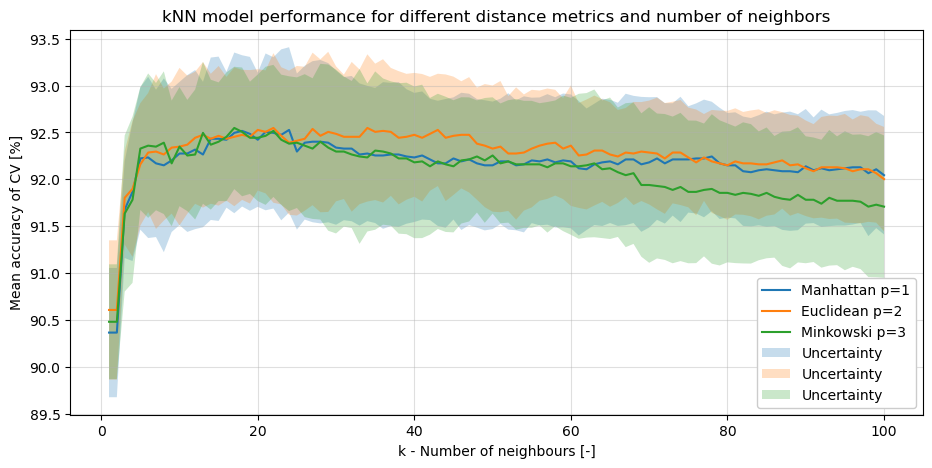

In [11]:
from sklearn.neighbors import KNeighborsClassifier
import time
import math

# Create a test and a train set. On the training set a 10-fold cross validation is performed. The best model is then evaluated on the test set
X_Train, X_Test, y_Train, y_Test = train_test_split(X_Robust, y, test_size=0.3, stratify=y, random_state=42) 

kmax = 100 # max neighbours to be tested, Reduce it this might take a while..
kNN_Accuracy_Avg = np.zeros((kmax,3)) # storage variable for average CV accuracy
kNN_Accuracy_Std = np.zeros((kmax,3))
# Grid search of parameters k and p
for i in range(3): # test three different values for the Minkowski parameter p, thereby evaluating different distance metrics 
    tic = time.time() # Start measuring time to get an idea which distance metric takes longer to compute
    for k in range(kmax): #test all models with k form 1 to n

        # Set up kNN classifier
        kNN = KNeighborsClassifier(n_neighbors=k+1, weights='distance', metric='minkowski', p=i+1) # Euclidean dist: p=1, Manhattan dist: p=2
        
        # Perform cross valdiation and store mean accuracy and data uncertainty scores
        kNN_scores = cross_val_score(kNN, X_Train, y_Train, cv=10)
        kNN_Accuracy_Avg[k,i] = np.mean(kNN_scores)    
        kNN_Accuracy_Std[k,i] = np.std(kNN_scores)  
    
    # Print best accuracy for each kernel and the corresponding best value for C  
    AccMax_index = np.argmax(kNN_Accuracy_Avg[:,i]) # index of best accurcy for current kernel
    print('Best accurracy for p=' +str(i+1)+ ' is \033[1m' + str(round(100*kNN_Accuracy_Avg[AccMax_index,i],2)) +' ± '+ str(round(100*kNN_Accuracy_Std[AccMax_index,i],2)) + '%\033[0m with \033[1mk=' + str(AccMax_index+1) + '\033[0m')
    print('  -> Time: ' + str(math.floor((time.time()-tic)/60)) +'min and ' +str(round((time.time()-tic) % 60))+ 's') # show elapsed time to fit nC models of on a given kernel 
    
# Plot results of "grid search"
plt.figure(figsize=(11, 5))
DistMetric = ['Manhattan p=1','Euclidean p=2','Minkowski p=3']
for i in range(3):
    plt.plot(np.arange(1, kmax+1),100*kNN_Accuracy_Avg[:,i], label=DistMetric[i] , zorder=2)
for i in range(3): # Separate loop to kee the legend tidy
    plt.fill_between(np.arange(1, kmax+1), 100*(kNN_Accuracy_Avg[:,i]-kNN_Accuracy_Std[:,i]), 100*(kNN_Accuracy_Avg[:,i]+kNN_Accuracy_Std[:,i]), zorder=1, alpha=0.25, label='Uncertainty')
plt.legend(loc='lower right', framealpha=1)
plt.title('kNN model performance for different distance metrics and number of neighbors')
plt.xlabel('k - Number of neighbours [-]')
plt.ylabel('Mean accuracy of CV [%]')
plt.grid(True, linestyle='-', alpha=0.4, zorder=1);      

Most important conclusion: The optimal value for k and p can vary significantly when running the code multiple times. Although for k between 5 and 30 and p between 1 and 3 the difference in performance is minimal (±0.5%).
The optimum changes as the split of the test and training set is randomly compiled each time. For computatinol reasons it is very expenisve to test higher powers than p=2. However it is not assumed that p>3 would improve the performance significantly. This was confirmed to some extent by manually testing different p-values up to p=10 at k=10.

Also the method for scaling the features has only little effect (±0.5%). It is not so important which one, but that a scaling is made at all, because without scaling the algorithm performs much worse. It is interesting to note that without scaling, the manhatten metric outperforms the other metrics by a wide margin. p=3 yields 71% at best, p=2 yields ~74% at best but p=1 yields almost 80% accuracy.

The accuracy of the model is largely independent of the used distance metric. However, it seems as the Manhattan metric performs slightly worse than Euclidean or Minkowski (p=3).
Also from k > 5 onwards the accuracy also reamins fairly constant with a slight downwards trend after k is about at 10. It is unlikely that higher values of k would improve the accuracy. Rather, it is to be expected that the accuracy will continue to decrease as more and more neighbors are used for classification. In all cases the weighting of the points by the inverse of the distance yielded better results and should also make the algorithm more robust when using high values for k.

### 4.2.1 Evaluation of best kNN on test set

Test set accuracy over all classes: 92.04%

Classification Report
--------------------------------------------------------
              precision    recall  f1-score      support
BARBUNYA       0.972678  0.896725  0.933159   397.000000
BOMBAY         1.000000  1.000000  1.000000   157.000000
CALI           0.939759  0.957055  0.948328   489.000000
DERMASON       0.909782  0.900376  0.905054  1064.000000
HOROZ          0.960276  0.961938  0.961106   578.000000
SEKER          0.934641  0.940789  0.937705   608.000000
SIRA           0.844933  0.874842  0.859627   791.000000
accuracy       0.920421  0.920421  0.920421     0.920421
macro avg      0.937438  0.933104  0.934997  4084.000000
weighted avg   0.921240  0.920421  0.920613  4084.000000


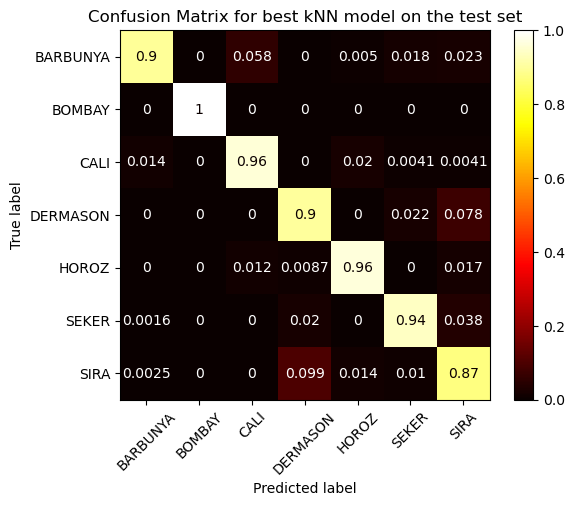

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from yellowbrick.classifier import ClassificationReport

# Use the best hyperparameters as discovered in the previous cell to set up an ideal classifier for the problem
kNN = KNeighborsClassifier(n_neighbors=22, weights='distance', metric='minkowski', p=2) # Euclidean dist: p=1, Manhattan dist: p=2
     
# Fit the final model on the whole taining set and predict using the untouched test set
y_Pred = kNN.fit(X_Train, y_Train).predict(X_Test)

print('Test set accuracy over all classes: \033[1m' + str(round(100*accuracy_score(y_Test,y_Pred),2)) + '%\033[0m\n')

# Display the confusion matrix for the kNN model with the parameters from the highest accuracy model from before
plt.rcdefaults()
CM = ConfusionMatrixDisplay.from_predictions(y_Test, y_Pred, normalize='true', xticks_rotation=45, cmap='hot')
plt.title('Confusion Matrix for best kNN model on the test set')

print('Classification Report\n--------------------------------------------------------')
kNN_CReport = pd.DataFrame(classification_report(y_Test, y_Pred, output_dict=True)).transpose()
print(kNN_CReport)

As can be seen from the confusion matrix the model has the biggest problems with Barbunya and Sira. Although the Barbunya seeds are easily classified by a human due to the distinct color, the ML algorithm cannot make use of this since there was no color extracted from the segmented images which is a missed opportunity. Bombay with its distinct features was 100% correct classified. Also the model seems to systemmatically missclassify Sira beans as Dermason and vice versa. However, these are also the most difficult for a human to classify when looking at the picture of the beans. 

Remark: In the original paper the authors used k=10 and the euclidean distance criterion which resutled in an accuracy of **92.52%** The result however, also depends on the random train-test split and was therefore not exactly reproducible. 

## 4.3 SVM

Test all available SVM kernels from sklearn namely ‘linear’, ‘poly’, ‘rbf’ and ‘sigmoid’ as well as differnt degerees for the polynomial and values for the regularization parameter C.

Best accurracy for rbf kernel is 93.37 ± 0.53% with C=35.11
  -> Time: 3min and 24s
Best accurracy for linear kernel is 92.63 ± 0.61% with C=4.33
  -> Time: 1min and 12s
Best accurracy for poly kernel is 92.68 ± 0.75% with C=100.0
  -> Time: 2min and 27s
Best accurracy for sigmoid kernel is 66.54 ± 1.0% with C=0.02
  -> Time: 3min and 12s


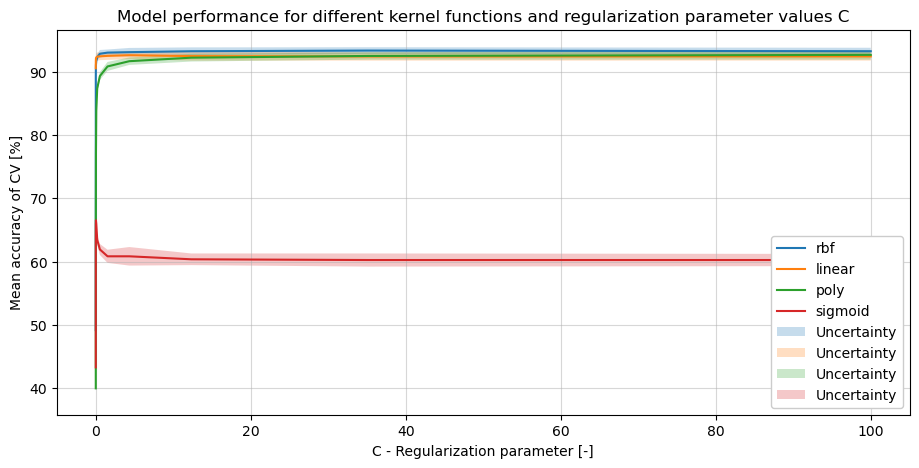

In [13]:
from sklearn.svm import SVC

# Create a test and a train set. On the training set a 10-fold cross validation is performed. The best model is then evaluated on the test set
X_Train, X_Test, y_Train, y_Test = train_test_split(X_Normal, y, test_size=0.3, stratify=y, random_state=42) 

nC = 12 # number of C values to test, values will be uniformly sampled from a logarithmic scale to scan a wide range
C = np.logspace(-3, 2, nC) # Test a wide range of values for C, the regularization parameter

SVM_Accuracy_Avg = np.zeros((nC,4)) # storage matrix for the average accuracy found in cross validation   
SVM_Accuracy_Std = np.zeros((nC,4))   
Kernels = ['rbf', 'linear', 'poly', 'sigmoid']

for i, Kern in enumerate(Kernels): # Test all common kernels
    tic = time.time() # Start measuring time
    for j, c in enumerate(C): 
    
        # Set up classifier
        SVM = SVC(kernel=Kern, C=c, class_weight="balanced")
    
        # Perform cross valdiation and store mean accuracy and data uncertainty scores 
        SVM_scores = cross_val_score(SVM, X_Train, y_Train, cv=10)    
        SVM_Accuracy_Avg[j,i] = np.mean(SVM_scores)    
        SVM_Accuracy_Std[j,i] = np.std(SVM_scores)  
    
    # Print best accuracy for each kernel and the corresponding best value for C  
    AccMax_index = np.argmax(SVM_Accuracy_Avg[:,i]) # index of best accurcy for current kernel
    print('Best accurracy for \033[1m' +Kern+ '\033[0m kernel is \033[1m' + str(round(100*SVM_Accuracy_Avg[AccMax_index,i],2)) +' ± '+ str(round(100*SVM_Accuracy_Std[AccMax_index,i],2)) + '%\033[0m with \033[1mC=' + str(round(C[AccMax_index],2)) + '\033[0m')
    print('  -> Time: ' + str(math.floor((time.time()-tic)/60)) +'min and ' +str(round((time.time()-tic) % 60))+ 's') # show elapsed time to fit nC models of on a given kernel 
    
# Plot results of "grid search"
plt.figure(figsize=(11, 5))
for i in range(4):
    plt.plot(C,100*SVM_Accuracy_Avg[:,i], label=Kernels[i] , zorder=2)
for i in range(4): # Separate loop to kee the legend tidy
    plt.fill_between(C, 100*(SVM_Accuracy_Avg[:,i]-SVM_Accuracy_Std[:,i]), 100*(SVM_Accuracy_Avg[:,i]+SVM_Accuracy_Std[:,i]), zorder=1, alpha=0.25, label='Uncertainty')
plt.legend(loc='lower right', framealpha=1)
plt.title('Model performance for different kernel functions and regularization parameter values C')
plt.xlabel('C - Regularization parameter [-]')
plt.ylabel('Mean accuracy of CV [%]')
plt.grid(True, linestyle='-', alpha=0.5, zorder=1);                                                                     

Looking at the performance of the different kernels, the linear and radial basis function (rbf) produced the best results with an accuracy of around 92%. For the polynomial kernel, values for degrees from 1 to 4 were tested, with 1 corresponding to the linear kernel. The performance decreased steadily as the degree increased. At grade 4, the best accuracy was only 88% with the maximum tested C of 25. The sigmoid kernel is significantly worse than the other kernels and only achieves around 60% accuracy.

For the regularization parameter C, there seems to be a plateau that is reached at high values, which means that low regularization is better for the model. The strength of the regularization is inversely proportional to the value of C. This is consistent with the findings from the logistic regression where the best results were also achieved without regularization

Not all scalers where tested due to the long training time. The robust scaler and the standard scaler yielded the results presented.

For this problem, SVM has a lower performance than the logistic regression model and a similar performance to kNN. The relatively long learning time of SVM, which does not translate into improved predictive power, makes SVM less attractive than the other models. Considering an ensemble voting classifier, including the SVM model in this case can be a bottleneck for training and inferecne time without contributing much to the overall performance.

Biggest learning from training SVM models: It takes a long time compared to the other algorithms. The models with non-linear kernels are not as fast to train because linear algebra canot unleash its power. The time complexity of training a SVM model with non-linear kernels scales with $O(N^2⋅M)$ or $O(n^3)$ depending on the specific kernel function, where N is the number of samples and M is the number of features. This makes training SVM models much slower, especially if there are many samples, than logistic regression which scales with $O(N⋅M)$ or kNN which needs no training and just has to compute each distance once per inference so $O(N)$.


### 4.3.1 Best SVM on test set

Test set accuracy over all classes: 92.46%

Classification Report
--------------------------------------------------------
              precision    recall  f1-score      support
BARBUNYA       0.930946  0.916877  0.923858   397.000000
BOMBAY         1.000000  1.000000  1.000000   157.000000
CALI           0.948665  0.944785  0.946721   489.000000
DERMASON       0.926499  0.900376  0.913251  1064.000000
HOROZ          0.960069  0.956747  0.958406   578.000000
SEKER          0.934295  0.958882  0.946429   608.000000
SIRA           0.857669  0.883692  0.870486   791.000000
accuracy       0.924584  0.924584  0.924584     0.924584
macro avg      0.936878  0.937337  0.937021  4084.000000
weighted avg   0.924992  0.924584  0.924671  4084.000000


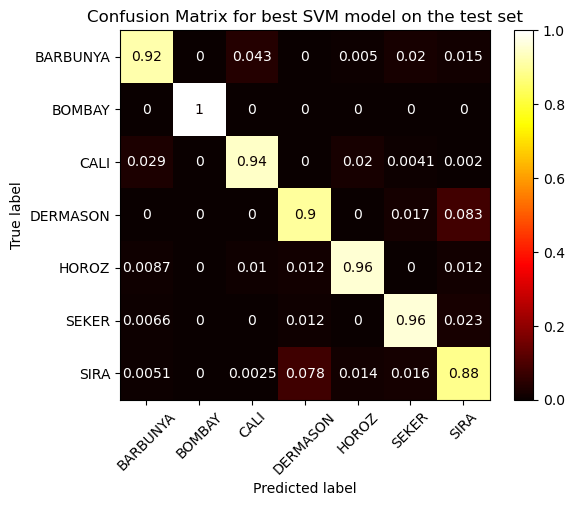

In [21]:
# Use the best hyperparameters as discovered in the previous cell to set up an ideal classifier for the problem
SVM = SVC(kernel='rbf', C=35.11, class_weight="balanced")
    
# Fit the final model on the whole taining set and predict using the untouched test set
y_Pred = SVM.fit(X_Train, y_Train).predict(X_Test)    

print('Test set accuracy over all classes: \033[1m' + str(round(100*accuracy_score(y_Test,y_Pred),2)) + '%\033[0m\n')

plt.rcdefaults()
CM = ConfusionMatrixDisplay.from_predictions(y_Test, y_Pred, normalize='true', xticks_rotation=45, cmap='hot')
plt.title('Confusion Matrix for best SVM model on the test set')

print('Classification Report\n--------------------------------------------------------')
SVM_CReport = pd.DataFrame(classification_report(y_Test, y_Pred, output_dict=True)).transpose()
print(SVM_CReport)

SVM seems to have difficulties with the same classes as logistic regression and kNN. Again the model was confused by Sira and Dermason. Although SVM has a completely different approach to predict the class, the same difficulties where encountered indicating that the problem is the data and not the modelling algorithm. For a better model, the data would have to be of better quality or better features would have to be extracted.

## 4.4. Decision Tree based classifiers

The last classifier that takes a closer look at the problem is the random forest classifier. It was choosen after comparing the accuracy of differnt classifiers that build all on the idea of decision trees namely Adaptive Boosting, Gradient Boosting and the well known Random Forest

In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA #just for fun test this too

# Create a test and a train set. On the training set a 10-fold cross validation is performed. The best model is then evaluated on the test set
X_Train, X_Test, y_Train, y_Test = train_test_split(X_Robust, y, test_size=0.3, stratify=y, random_state=42) 

DT  = DecisionTreeClassifier()
RF  = RandomForestClassifier()
AB  = AdaBoostClassifier()
GB  = GradientBoostingClassifier()
lda = LDA(n_components=2)

y_Pred_DT  = DT.fit(X_Train,y_Train).predict(X_Test)
y_Pred_RF  = RF.fit(X_Train,y_Train).predict(X_Test)
y_Pred_AB  = AB.fit(X_Train,y_Train).predict(X_Test)
y_Pred_GB  = GB.fit(X_Train,y_Train).predict(X_Test)
y_Pred_LDA = lda.fit(X_Train,y_Train).predict(X_Test)

# Print accuracy of each estimator with default settings
print('Decision Tree: \t\t\t'+ str(round(100*accuracy_score(y_Pred_DT, y_Test),2)) + '%')
print('Random Forest: \t\t\t\033[1m'+ str(round(100*accuracy_score(y_Pred_RF, y_Test),2)) + '%\033[0m')
print('AdaBoost: \t\t\t'+ str(round(100*accuracy_score(y_Pred_AB, y_Test),2)) + '%')
print('GradientBoosting: \t\t'+ str(round(100*accuracy_score(y_Pred_GB, y_Test),2)) + '%')
print('LinearDiscriminantAnalysis: \t'+ str(round(100*accuracy_score(y_Pred_LDA, y_Test),2)) + '%')

Decision Tree: 			89.32%
Random Forest: 			92.21%
AdaBoost: 			47.06%
GradientBoosting: 		91.94%
LinearDiscriminantAnalysis: 	90.4%


Since the random forest classifier showed the highest accuracy it was choosen as the last classifier for the ensemble voting classifier. It is intersting to see that the Adaptive Boosting algorithm performed much worse than the others. This might be because of the imbalanced data set. AdaBoost may give more importance to the minority class and struggle to perform well on the majority class.


## 4.4.1 Random Forest

Best accurracy for gini criterion is 92.7 ± 0.89% with 116 trees in the forest
  -> Time: 8min and 29s
Best accurracy for entropy criterion is 92.73 ± 1.07% with 144 trees in the forest
  -> Time: 9min and 1s
Best accurracy for log_loss criterion is 92.71 ± 0.9% with 200 trees in the forest
  -> Time: 9min and 2s


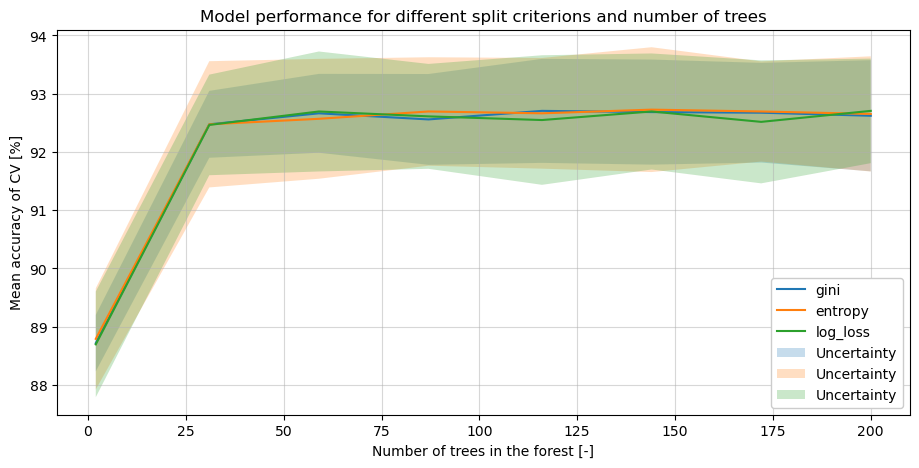

In [16]:
# Create a test and a train set. On the training set a 10-fold cross validation is performed. The best model is then evaluated on the test set
X_Train, X_Test, y_Train, y_Test = train_test_split(X_Normal, y, test_size=0.3, stratify=y, random_state=42) 

maxSample = 8; # max number of samples (number of trees) to be drawn from a uniform distribution of trees
Forest_Size = np.ceil(np.linspace(2,200,maxSample)).astype(int); # set up grid

RF_Accuracy_Avg = np.zeros((maxSample,3)) # storage matrix for the average accuracy found in cross validation   
RF_Accuracy_Std = np.zeros((maxSample,3))   
Criterion = ['gini', 'entropy', 'log_loss']

for i, Crit in enumerate(Criterion): # Test different split criterions
    tic = time.time() # Start measuring time
    for j, nTrees in enumerate(Forest_Size): # test the size of the forest
        
        # Set up classifier
        Taiga = RandomForestClassifier(n_estimators=nTrees, criterion=Crit)
        
        # Perform cross valdiation and store mean accuracy and data uncertainty scores 
        RF_scores = cross_val_score(Taiga, X_Train, y_Train, cv=10)    
        RF_Accuracy_Avg[j,i] = np.mean(RF_scores)    
        RF_Accuracy_Std[j,i] = np.std(RF_scores)  
    
    # Print best accuracy for each kernel and the corresponding best value for C  
    AccMax_index = np.argmax(RF_Accuracy_Avg[:,i]) # index of best accurcy for current kernel
    print('Best accurracy for \033[1m' +Crit+ '\033[0m criterion is \033[1m' + str(round(100*RF_Accuracy_Avg[AccMax_index,i],2)) +' ± '+ str(round(100*RF_Accuracy_Std[AccMax_index,i],2)) + '%\033[0m with \033[1m' + str(Forest_Size[AccMax_index]) + '\033[0m trees in the forest')
    print('  -> Time: ' + str(math.floor((time.time()-tic)/60)) +'min and ' +str(round((time.time()-tic) % 60))+ 's') # show elapsed time to fit nC models of on a given kernel 
    
# Plot results of "grid search"
plt.figure(figsize=(11, 5))
for i in range(3):
    plt.plot(Forest_Size,100*RF_Accuracy_Avg[:,i], label=Criterion[i] , zorder=2)
for i in range(3): # Separate loop to kee the legend tidy
    plt.fill_between(Forest_Size, 100*(RF_Accuracy_Avg[:,i]-RF_Accuracy_Std[:,i]), 100*(RF_Accuracy_Avg[:,i]+RF_Accuracy_Std[:,i]), zorder=1, alpha=0.25, label='Uncertainty')
plt.legend(loc='lower right', framealpha=1)
plt.title('Model performance for different split criterions and number of trees')
plt.xlabel('Number of trees in the forest [-]')
plt.ylabel('Mean accuracy of CV [%]')
plt.grid(True, linestyle='-', alpha=0.5, zorder=1);   

As can be seen from the graph above, the splitting criterion has no major influence (Std:~ ±1%) on the model performance. As for the number of trees in the forest it seem to reach quickly a plateau. The plateau is reached from 60 trees onwards, after which there is no more performance growth worth mentioning. The average accuracy is in the same region as for kNN and SVM. So far logistic regression stands out in terms of performance. Because it takes a long time to test large forests only up to 200 trees was tested. Single runs on large forests with more than 1000 trees showed no significant increase in performance.

### 4.4.2 Best Random Forest on test set

Test set accuracy over all classes: 92.61%

Classification Report
--------------------------------------------------------
              precision    recall  f1-score      support
BARBUNYA       0.944297  0.896725  0.919897   397.000000
BOMBAY         1.000000  1.000000  1.000000   157.000000
CALI           0.934959  0.940695  0.937819   489.000000
DERMASON       0.918233  0.918233  0.918233  1064.000000
HOROZ          0.955403  0.963668  0.959518   578.000000
SEKER          0.947541  0.950658  0.949097   608.000000
SIRA           0.870162  0.881163  0.875628   791.000000
accuracy       0.926053  0.926053  0.926053     0.926053
macro avg      0.938657  0.935878  0.937170  4084.000000
weighted avg   0.926226  0.926053  0.926069  4084.000000


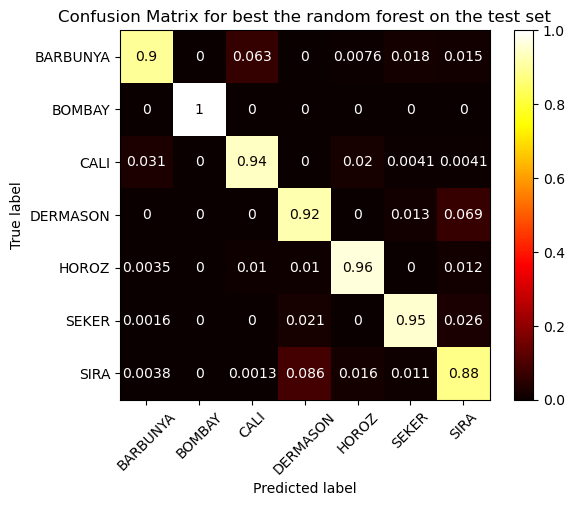

In [22]:
# Use the best hyperparameters as discovered in the previous cell to set up an ideal classifier for the problem
Taiga = RandomForestClassifier(n_estimators=144, criterion='entropy', random_state=42)
    
# Fit the final model on the whole taining set and predict using the untouched test set
y_Pred = Taiga.fit(X_Train, y_Train).predict(X_Test)    

print('Test set accuracy over all classes: \033[1m' + str(round(100*accuracy_score(y_Test,y_Pred),2)) + '%\033[0m\n')

plt.rcdefaults()
CM = ConfusionMatrixDisplay.from_predictions(y_Test, y_Pred, normalize='true', xticks_rotation=45, cmap='hot')
plt.title('Confusion Matrix for best the random forest on the test set')

print('Classification Report\n--------------------------------------------------------')
RF_CReport = pd.DataFrame(classification_report(y_Test, y_Pred, output_dict=True)).transpose()
print(RF_CReport)

And again, the same pattern of misclassification can be seen. Sira and Dermason are simply the most difficult to distinguish. And here, too, Barbunya has a hard time compared to the others.

## 4.5. PCA

Before testing the ensemble voting classifier lets check if a lower dimensional representation of the data helps the individual models to perform better. For this the data set is projected into a latent space which captures the "essence" of the original dataset in a new dataset with less features. This is done by computing the first n principal components and using them to project the data into a (hopefully) more usefull represntation. However, PCA is most usefull with very high dimensional data where the features are highly colinear and contain noise for example in spectroscopic datasets. For the data set here there might not be a big benefit or even a drop in performance if all features are important and the data cannot be shrunken down to a lower dimensional space without losing usefull correlations. 

All models will be tested on all numbers of principal componetns up to the maximum of 16. 

Best accurracy for Logistic Regression classififer is 91.64 ± 0.67% with 16, principal components
  -> Time: 0min and 15s
Best accurracy for kNN classififer is 92.6 ± 0.77% with 16, principal components
  -> Time: 0min and 6s
Best accurracy for SVM classififer is 93.26 ± 0.55% with 16, principal components
  -> Time: 2min and 3s
Best accurracy for Random Forest classififer is 93.28 ± 0.64% with 16, principal components
  -> Time: 18min and 26s


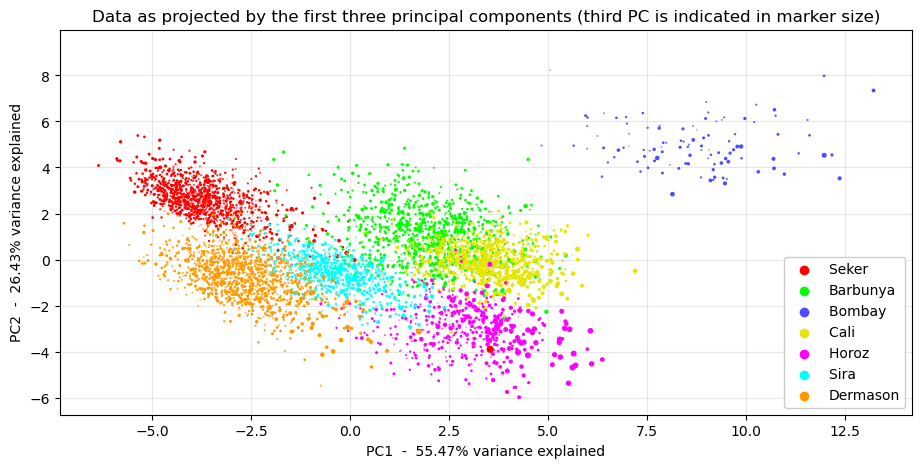

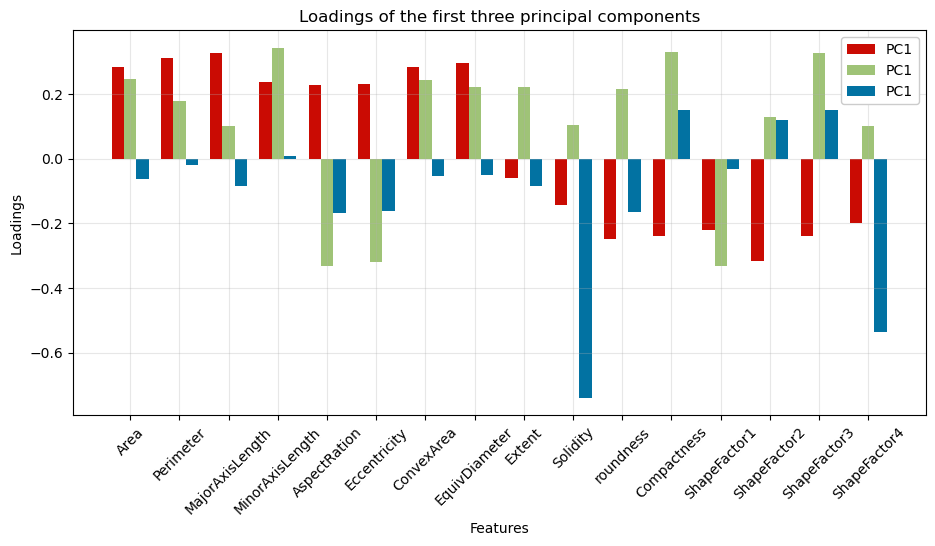

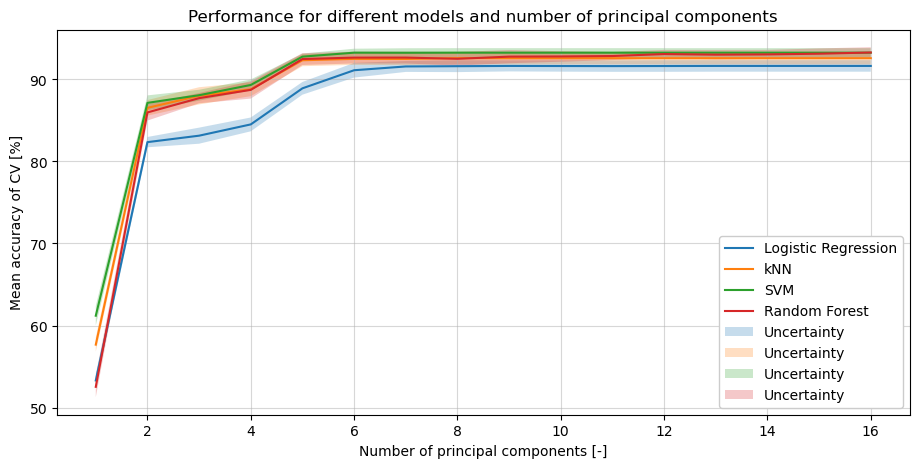

In [19]:
from sklearn.decomposition import PCA

#--compute full component PCA------------------------------------------------------------------------------------------------
n_components = 16
pca = PCA(n_components=n_components)

# Fit PCA to the data and transform it
X_pca = pca.fit_transform(X_Normal)

# Get the loadings (principal axes) from the PCA components
Loadings = pca.components_.T
PC1 = X_Normal.dot(Loadings[:,0])
PC2 = X_Normal.dot(Loadings[:,1])
PC3 = X_Normal.dot(Loadings[:,2])

# Make a matrix for coloring each class according to the previously defined colors in "Colors"
for i in range(len(nSamples_per_Class)):
    Red   = Colors[i,0]*np.ones((nSamples_per_Class[i],1))
    Green = Colors[i,1]*np.ones((nSamples_per_Class[i],1))
    Blue  = Colors[i,2]*np.ones((nSamples_per_Class[i],1))
    if i == 0:
        Color_Matrix = np.column_stack((Red,Green,Blue))
    else:
        Inter_RGB = np.column_stack((Red,Green,Blue))
        Color_Matrix = np.vstack((Color_Matrix,Inter_RGB))
        
plt.figure(figsize=(11, 5))
plt.scatter(PC1,PC2,PC3, color=Color_Matrix, zorder=2)
plt.title('Data as projected by the first three principal components (third PC is indicated in marker size)')
plt.xlabel('PC1  -  ' + str(round(100*pca.explained_variance_ratio_[0],2)) + '% variance explained')
plt.ylabel('PC2  -  ' + str(round(100*pca.explained_variance_ratio_[1],2)) + '% variance explained')
plt.grid(True, linestyle='-', alpha=0.3, zorder=1); 
# Add legend
for color, label in zip(Colors, Target_Class_Strings):
    plt.scatter([], [], c=color, label=label)
plt.legend(framealpha=1)

#-Plot the loadings of the first three PC to see i there are any patterns
plt.figure(figsize=(11, 5))
Features_Lables = list(Bean_DataFrame.columns.values);
Features_Lables = Features_Lables[:-1] # remove target lables 'class'
index = np.arange(1, 17)
Width = 0.25
plt.bar(index - Width, Loadings[:,0], Width, color='r', label='PC1')
plt.bar(index        , Loadings[:,1], Width, color='g', label='PC1')
plt.bar(index + Width, Loadings[:,2], Width, color='b', label='PC1')
plt.legend(framealpha=1)
plt.title('Loadings of the first three principal components')
plt.xlabel('Features')
plt.ylabel('Loadings')
plt.grid(True, linestyle='-', alpha=0.3, zorder=1); 
plt.xticks(index, Features_Lables, rotation=45);
#---------------------------------------------------------------------------------------------------------------------------
# Train a model on the first n principal components

# Set up each estimator whith the previously found hyperparameters
LogReg  = LogisticRegression(solver='liblinear', random_state=42)
kNN     = KNeighborsClassifier(n_neighbors=22, weights='distance', metric='minkowski', p=2)
SVM     = SVC(kernel='rbf', C=35.11, class_weight="balanced", random_state=42)
RF      = RandomForestClassifier(n_estimators=144, criterion='entropy')
Classifiers = [LogReg, kNN, SVM, RF] 
Classifier_Names = ['Logistic Regression','kNN','SVM','Random Forest']

PCA_Accuracy_Avg = np.zeros((16,4)) # storage matrix for the average accuracy found in cross validation   
PCA_Accuracy_Std = np.zeros((16,4)) 

for i, Classy in enumerate(Classifiers):    
    tic = time.time() # Start measuring time
    for j in range(16):
        
        # Project the scaled features into a (hopefully) usefull latent space using the first i PC
        pca = PCA(n_components=j+1)
        X_PCA = pca.fit_transform(X_Normal)
            
        # Create a test and a train set from the transformed features. On the training set a 10-fold cross validation is performed. The best model is then evaluated on the test set
        X_Train, X_Test, y_Train, y_Test = train_test_split(X_PCA, y, test_size=0.3, stratify=y, random_state=42) 
        
        # Perform cross valdiation and store mean accuracy and data uncertainty scores 
        PCA_scores = cross_val_score(Classy, X_Train, y_Train, cv=10)    
        PCA_Accuracy_Avg[j,i] = np.mean(PCA_scores)    
        PCA_Accuracy_Std[j,i] = np.std(PCA_scores)  
        
    # Print best accuracy for each classifier and the corresponding number of components
    AccMax_index = np.argmax(PCA_Accuracy_Avg[:,i]) # index of best accurcy for current kernel
    print('Best accurracy for \033[1m' +Classifier_Names[i]+ '\033[0m classififer is \033[1m' + str(round(100*PCA_Accuracy_Avg[AccMax_index,i],2)) +' ± '+ str(round(100*PCA_Accuracy_Std[AccMax_index,i],2)) + '%\033[0m with \033[1m' + str(j+1) + '\033[0m, principal components')
    print('  -> Time: ' + str(math.floor((time.time()-tic)/60)) +'min and ' +str(round((time.time()-tic) % 60))+ 's') # show elapsed time to fit nC models of on a given kernel 
        
# Plot results of "grid search"
plt.figure(figsize=(11, 5))
for i in range(4):
    plt.plot(np.arange(1, 17),100*PCA_Accuracy_Avg[:,i], label=Classifier_Names[i] , zorder=2)
for i in range(4): # Separate loop to kee the legend tidy
    plt.fill_between(np.arange(1, 17), 100*(PCA_Accuracy_Avg[:,i]-PCA_Accuracy_Std[:,i]), 100*(PCA_Accuracy_Avg[:,i]+PCA_Accuracy_Std[:,i]), zorder=1, alpha=0.25, label='Uncertainty')
plt.legend(loc='lower right', framealpha=1)
plt.title('Performance for different models and number of principal components')
plt.xlabel('Number of principal components [-]')
plt.ylabel('Mean accuracy of CV [%]')
plt.grid(True, linestyle='-', alpha=0.5, zorder=1); 

Training models on data transformed with the loading vectors from PCA did not bring any improvement, as can be seen from the graph above. This was to be expected as the original dataset did not contain very collinear high dimensional data and there is not much noise/random variance in the features. This is a consequence of the careful sample preparation and feature extraction with the high-resolution camera.

However, the plot of the data based on the first 2-3 principal components shows visually that the classes are well clustered and therefore readily separable / classifiable.
     

## 5. Ensemble Classifier

Now lets finally see if all the tested estimators can together improve the performance in a ensemble voting classifier.

Classification Report
--------------------------------------------------------
              precision    recall  f1-score      support
BARBUNYA       0.954907  0.906801  0.930233   397.000000
BOMBAY         1.000000  1.000000  1.000000   157.000000
CALI           0.950719  0.946830  0.948770   489.000000
DERMASON       0.915094  0.911654  0.913371  1064.000000
HOROZ          0.958692  0.963668  0.961173   578.000000
SEKER          0.934959  0.945724  0.940311   608.000000
SIRA           0.861214  0.878635  0.869837   791.000000
accuracy       0.924829  0.924829  0.924829     0.924829
macro avg      0.939369  0.936187  0.937671  4084.000000
weighted avg   0.925186  0.924829  0.924923  4084.000000


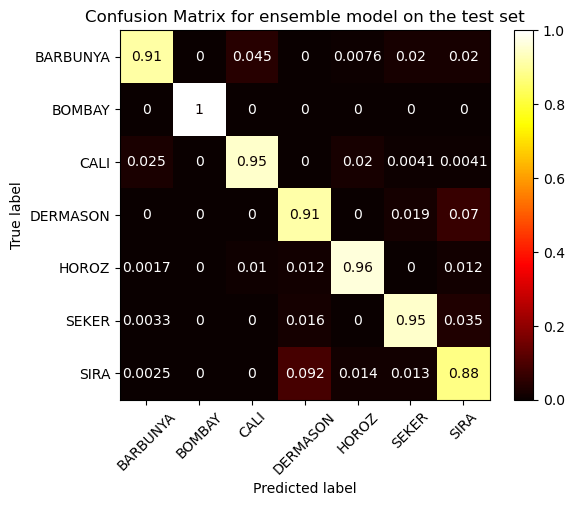

In [24]:
from sklearn.ensemble import VotingClassifier

# Create a test and a train set. On the training set a 10-fold cross validation is performed. The best model is then evaluated on the test set
X_Train, X_Test, y_Train, y_Test = train_test_split(X_Normal, y, test_size=0.3, stratify=y, random_state=42) 

# Define individual classifiers
LogReg  = OneVsRestClassifier(LogisticRegression(solver='liblinear', random_state=42))  # same one-vs-rest scheme as in section 4.1
kNN = KNeighborsClassifier(n_neighbors=22, weights='distance', metric='minkowski', p=2)
SVM = SVC(kernel='rbf', C=35.11, class_weight="balanced", probability=True, random_state=42)
RF  = RandomForestClassifier(n_estimators=144, criterion='entropy', random_state=42)

# Create a VotingClassifier from the individual estimators
Ensemble_Classifier = VotingClassifier(
    estimators=[
        ('LogReg', LogReg),
        ('kNN', kNN),
        ('SVM', SVM),
        ('RF', RF),
    ],
    voting='soft')  # Use 'hard' for majority voting, 'soft' for weighted voting based on class probabilities

y_Pred = Ensemble_Classifier.fit(X_Train, y_Train).predict(X_Test)
Acc_Ensemle = accuracy_score(y_Pred,y_Test)

plt.rcdefaults()
CM = ConfusionMatrixDisplay.from_predictions(y_Test, y_Pred, normalize='true', xticks_rotation=45, cmap='hot')
plt.title('Confusion Matrix for ensemble model on the test set')

print('Classification Report\n--------------------------------------------------------')
Ensemle_CReport = pd.DataFrame(classification_report(y_Test, y_Pred, output_dict=True)).transpose()
print(Ensemle_CReport)

There is a small but not significant improve in performance compared to all models exept logistic regression. It seems as all classifiers encounter similar problems with the same classes thus the voting can not benefit from the combined effort of all models since all of them vote more or less for the same class. The small boost in perfomance might be only due to the "veto" of the logistc regression model.

For comparison, the accuracy scores for the models trained by Koklu et al. and the ones tested in this work are shown in the cell below.

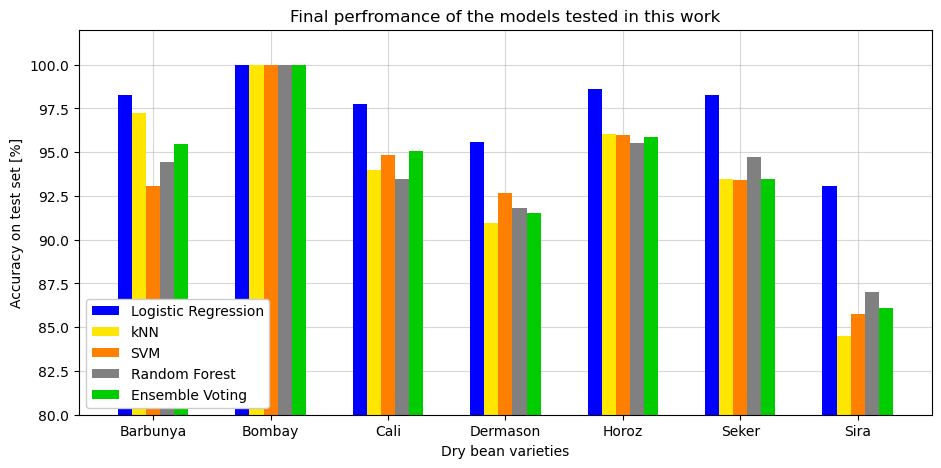

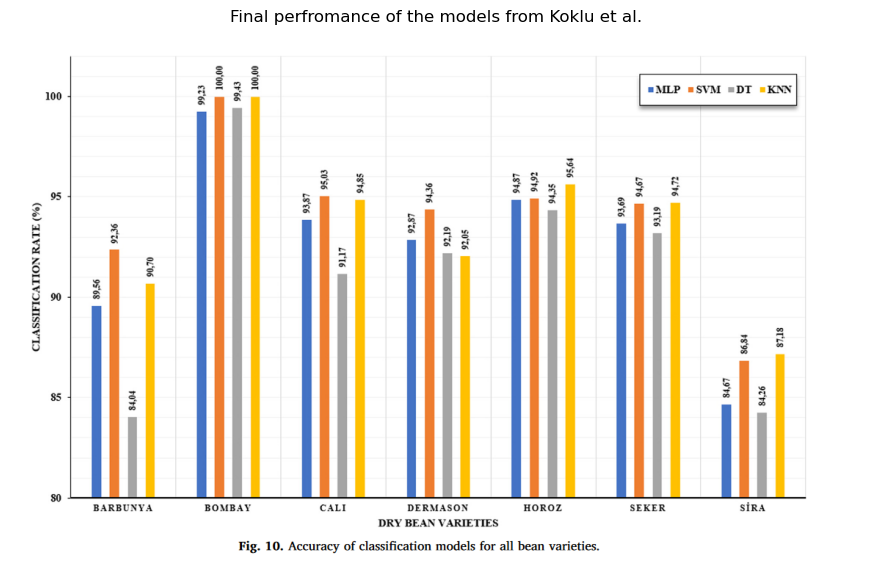

In [25]:
import os

# Per-class recall (= fraction of the beans of a class that were classified correctly) on the common test set.
# Recall is used for all models, so the bars are directly comparable.
Class_Order = ['BARBUNYA','BOMBAY','CALI','DERMASON','HOROZ','SEKER','SIRA']
Final_Reports = [('Logistic Regression', LogReg_CReport , [0,0,1]   ),
                 ('kNN'                , kNN_CReport    , [1,.9,0]  ),
                 ('SVM'                , SVM_CReport    , [1,.5,0]  ),
                 ('Random Forest'      , RF_CReport     , [.5,.5,.5]),
                 ('Ensemble Voting'    , Ensemle_CReport, [0,.8,0]  )]

bar_width = 0.15
positions = np.arange(len(Class_Order))
plt.figure(figsize=(11, 5))
for k, (Name, CReport, Color) in enumerate(Final_Reports):
    Overall = 100*CReport.loc['accuracy', 'precision']  # overall accuracy is stored in every column of this row
    plt.bar(positions + (k - 2)*bar_width, 100*CReport.loc[Class_Order, 'recall'], bar_width,
            label=Name + ' (overall ' + str(round(Overall, 1)) + '%)', color=Color, zorder=2)
plt.title('Final performance of the models tested in this work')
plt.xlabel('Dry bean varieties')
plt.ylabel('Recall on test set [%]')
plt.xticks(positions, [Name.capitalize() for Name in Class_Order])
plt.legend(loc='lower left', framealpha=1)
plt.ylim(75,101)
plt.grid(True, linestyle='-', alpha=0.5, zorder=1)
plt.savefig('Final_Result_BarChart.png', dpi=150, bbox_inches='tight')

# Plot the results form Koklu et al. to compare them with the findings in this work (only if the image is available)
if os.path.exists('PaperClassificationModel_Accuracy.png'):
    plt.figure(figsize=(11, 10))
    plt.imshow(mpimg.imread('PaperClassificationModel_Accuracy.png'))
    plt.axis('off')
    plt.title('Final perfromance of the models from Koklu et al.');

## 5.1 Conclusion

The ensemble voting classifier could not outperform the logistic regression model, which is by far (~+5% accuracy) the best model. The reason for this is that all other models had difficulties with the same classes, namely Barbunya, Dermason and Sira. This shows that an ensemble classifier works best when each model can compensate for the weaknesses of another. If all models vote for the same class, there is no point in combining them into an ensemble voting classifier.

In conclusion, logistic regression is the most suitable algorithm for this problem. 

## 6. Future Work

Models sometimes struggle to classify Barbunya beans, although the difference in color is striking to humans. This is a missed opportunity because one could have extracted the average color values of the pixels in the bean area before converting to black and white and used the RGB values as new features. As the Barbunya is the only brownish bean, it could easily be distinguished from the others, similar to how the large Bombay beans stand out due to their size. 

It might be useful to use pictures directly and use a neural network to classify the beabs based on the information in the whole image. This woudl not only save the step of feature extraction but also enable/force the model to generalize by himself and maybe the model can then also be trained with differnt image backgrounds so that the model really has to learn from the pixels what a certain type of bean is. Then one could use the model "in the field". Take a picture with and predict the class on the spot.